## Weak Auger search: electron–electron correlations and ion gates
Can photoelectron–Auger correlations in gas-phase glycine, eventually associated with Gly²⁺, be recovered when the ordinary electron spectrum is weak? Inspect detector coverage first, then ion TOF, unique two-hit coincidence, ordinary/GMD partial covariance, moving photoelectron projections and configurable ion gates. No Auger energy window is imposed.

**Inputs:** config-1 `glycine_delay_scan_7June_147C_{274.0,274.5,275.0,275.5,276.0,276.5}eV.h5` and matching `_aggregates_tr_etof1.h5`, discovered through `config.COMBINED_DIR`. The provenance cell prints actual paths, source shapes and recorded run numbers; missing run numbers remain unassigned. Reference conventions are the 7 June section in `Bunch investigations.ipynb` / `Data 2D maps.ipynb`, `covariance_inspect_cfg1.ipynb` and `compute_aggregates.py`.

**Execution:** defaults are a small preview (8 retained trains per file, 1 occupied aggregate cell per file). Preview raw and aggregate populations differ and are labelled. Full scans and full aggregate pooling must run with a **Slurm compute-node notebook kernel**, setting both preview limits to `None`. Chunking limits memory, not runtime. Do not run the full scan on a Maxwell login/display node. Raw H5 files are opened read-only; this notebook writes no experimental data.

**Assignments pending:** no exported ion mass calibration or established 10a′ binding-energy window was found. Set `PE_BE_WINDOW_EV` and ion ROIs only after justifying them. Their sections safely report “unset” until configured. A visual peak alone does not establish an Auger channel or a charge-state assignment.

In [1]:
# Imports: locate this checkout without absolute paths; respect FLASH_ENV if supplied.
import os, sys, json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

os.environ.setdefault("FLASH_ENV", "remote")
repo_root = next((p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents] if (p / "analysis/scripts/config.py").is_file()), None)
if repo_root is None: raise RuntimeError("Start this notebook within the glycine26 checkout")
for folder in [repo_root / "analysis/scripts", repo_root / "analysis/post"]:
    if str(folder) not in sys.path: sys.path.insert(0, str(folder))
import config
from ee_ion_covariance import (discover_datasets, inspect_coverage, histogram_from_counter, make_ke_edges,
    accumulate_pairs, coincidence_projection, read_ee_aggregates)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "axes.spines.top": False, "axes.spines.right": False})

In [9]:
# All analysis choices live here. TOF uses the saved calibration's 100 ps units.
PHOTON_ENERGIES_EV = [274.0, 274.5, 275.0, 275.5, 276.0, 276.5]
# PHOTON_ENERGIES_EV = [274.0]
KE_ANALYSIS_RANGE = (10.0, 280.0)
RUN_COVERAGE_DIAGNOSTIC = False
SCAN_STEM = "glycine_delay_scan_7June_147C"
AGG_SUFFIX = "_aggregates_tr_etof1.h5"
CALIB_PATH = Path(config.COMBINED_DIR).parent / "Calibrations/etof_energy_calibration_t0_scan.json"
BUNCH_RANGE, GMD_RANGE = (0, 101), (0, 24.0) # Original raw 7 June population.
ETOF_PLOT_RANGE, KE_PLOT_RANGE = None, KE_ANALYSIS_RANGE
TOF_BIN_WIDTH, KE_BIN_WIDTH_EV = 1.0, 1.0
ION_TOF_PLOT_RANGE, ION_TOF_BIN_WIDTH = None, 20.0
CHUNK_TRAINS, MAX_TRAINS = 250, None  # None for all trains, only on a Slurm compute node.
MAX_KE_BINS = 1500  # Fail explicitly if anomalous coverage makes the dense map too large.
DELAY_WINDOW_FS, DELAY_ZERO_STAGE, FS_PER_STAGE_UNIT = None, 0.0, 3.33 / 10000.0
USE_CB, CB_FILES = False, {}  # hv -> relative .npy path under config.COMBINED_DIR.
AGG_GMD_RANGE = (0.0, 24.0)  # Exact existing GMD edges; 1–12 cannot be recovered from these aggregates.
MAX_AGG_CELLS = None
AGG_STAGE_RANGE,  AGG_ROW_CHUNK = None, 64
PE_BE_WINDOW_EV = None  # Required (BE_low, BE_high) for a justified 10a′ assignment; no assumed Auger ROI.
ION_SIGNAL_ROI, ION_CONTROL_ROI = None, None  # (TOF_low, TOF_high), generic labels until assigned.
SHOW_SUMMED, COINCIDENCE_LOG, EXCLUDE_COV_DIAGONAL_IN_PROJECTION = True, True, True

ke_edges = np.arange(KE_ANALYSIS_RANGE[0], KE_ANALYSIS_RANGE[1] + KE_BIN_WIDTH_EV, KE_BIN_WIDTH_EV)
ke_centres = 0.5 * (ke_edges[:-1] + ke_edges[1:])
ke_widths = np.diff(ke_edges)

settings = dict(bunch_range=BUNCH_RANGE, gmd_range=GMD_RANGE, chunk_trains=CHUNK_TRAINS, max_trains=MAX_TRAINS,
    tof_bin_width=TOF_BIN_WIDTH, ion_bin_width=ION_TOF_BIN_WIDTH, delay_window_fs=DELAY_WINDOW_FS,
    delay_zero_stage=DELAY_ZERO_STAGE, fs_per_stage_unit=FS_PER_STAGE_UNIT)
if PE_BE_WINDOW_EV is not None and not (len(PE_BE_WINDOW_EV) == 2 and PE_BE_WINDOW_EV[0] < PE_BE_WINDOW_EV[1]):
    raise ValueError("PE_BE_WINDOW_EV must be (BE_low, BE_high)")
with CALIB_PATH.open() as f: calibration = json.load(f)
if calibration.get("tof_units") != "100 ps": raise ValueError("Verify TOF units before analysis")
datasets = discover_datasets(config.COMBINED_DIR, PHOTON_ENERGIES_EV, SCAN_STEM, AGG_SUFFIX)
print("Environment:", config.FLASH_ENV, "Calibration:", CALIB_PATH)
print("Calibration t0/slope/E0:", [calibration[k] for k in ["t0_tof_units", "slope_eV_tof_unit2", "E0_eV"]])
print("Selections:", settings, "Cb:", USE_CB)
print("RAW PREVIEW" if MAX_TRAINS is not None else "FULL RAW DATA", "/ AGGREGATE PREVIEW" if MAX_AGG_CELLS is not None else "/ FULL AGGREGATE POOL")
for ds in datasets:
    print(f"{ds['hv']:.1f} eV | run={ds['run_no']} | shape={ds['shape']} | trim={ds['trim_start']}/{ds['trim_end']}")
    print(" raw:", ds['source'], "\n aggregate:", ds['aggregate'], "\n shapes:", ds['aggregate_shapes'])

Environment: remote Calibration: /asap3/flash/gpfs/fl24/2026/data/11022188/processed/Calibrations/etof_energy_calibration_t0_scan.json
Calibration t0/slope/E0: [70.31711711711705, 172656057.91151598, -32.01574693372097]
Selections: {'bunch_range': (0, 101), 'gmd_range': (0, 24.0), 'chunk_trains': 250, 'max_trains': None, 'tof_bin_width': 1.0, 'ion_bin_width': 20.0, 'delay_window_fs': None, 'delay_zero_stage': 0.0, 'fs_per_stage_unit': 0.000333} Cb: False
FULL RAW DATA / FULL AGGREGATE POOL
274.0 eV | run=not recorded | shape=(27291, 101) | trim=3/3
 raw: /asap3/flash/gpfs/fl24/2026/data/11022188/processed/combined/glycine_delay_scan_7June_147C_274.0eV.h5 
 aggregate: /asap3/flash/gpfs/fl24/2026/data/11022188/processed/combined/glycine_delay_scan_7June_147C_274.0eV_aggregates_tr_etof1.h5 
 shapes: {'D': (4, 53, 5000), 'DtD': (4, 53, 5000, 5000), 'G': (4, 53), 'DtG': (4, 53, 5000), 'GtG': (4, 53), 'n_per_bin': (4, 53)}
274.5 eV | run=not recorded | shape=(34147, 101) | trim=3/3
 raw: /as

In [10]:
# --- Aggregate statistics by GMD bin -------------------------------------
import h5py
for ds in datasets:
    with h5py.File(ds["aggregate"], "r") as f:
        edges = f["gmd_edges"][:]
        n = f["n_per_bin"][:]

        # Sum over delay axis if present.
        shots = np.sum(n, axis=tuple(range(1, n.ndim))) if n.ndim > 1 else n

        print(f"\n{ds['hv']:g} eV")
        for i in range(len(edges) - 1):
            print(f"  {edges[i]:g}-{edges[i + 1]:g} uJ: {int(shots[i]):,} shots")


274 eV
  0-3 uJ: 728,160 shots
  3-6 uJ: 825,160 shots
  6-12 uJ: 943,001 shots
  12-24 uJ: 169,341 shots

274.5 eV
  0-3 uJ: 1,005,647 shots
  3-6 uJ: 1,059,379 shots
  6-12 uJ: 1,098,440 shots
  12-24 uJ: 168,585 shots

275 eV
  0-3 uJ: 1,048,783 shots
  3-6 uJ: 1,131,404 shots
  6-12 uJ: 1,037,486 shots
  12-24 uJ: 125,118 shots

275.5 eV
  0-3 uJ: 1,238,469 shots
  3-6 uJ: 1,065,606 shots
  6-12 uJ: 925,981 shots
  12-24 uJ: 102,383 shots

276 eV
  0-3 uJ: 1,540,629 shots
  3-6 uJ: 947,131 shots
  6-12 uJ: 760,515 shots
  12-24 uJ: 83,750 shots

276.5 eV
  0-3 uJ: 5,382,593 shots
  3-6 uJ: 0 shots
  6-12 uJ: 0 shots
  12-24 uJ: 0 shots


In [11]:
# Electron-only accumulation; required inputs do not depend on the optional coverage cell.
cb_by_energy = {}
if USE_CB:
    for hv in PHOTON_ENERGIES_EV:
        if hv not in CB_FILES: raise ValueError("Cb learner has no exported API: supply previously validated per-bunch CB_FILES")
        relative = Path(CB_FILES[hv])
        if relative.is_absolute() or '..' in relative.parts: raise ValueError("CB_FILES must be relative to config.COMBINED_DIR")
        cb_by_energy[hv] = np.load(Path(config.COMBINED_DIR) / relative, allow_pickle=False)
raw = {ds['hv']: accumulate_pairs(ds, settings, calibration, ke_edges, cb=cb_by_energy.get(ds['hv']))['ungated'] for ds in datasets}


## 1. Optional detector coverage inspection
Does the recorded electron channel contain lower-KE events? Stream all positive finite hits on the selected shots without a TOF/KE cut. The full recorded TOF spectrum includes events outside the calibration domain; only `TOF > t0` maps to KE. Negative calibrated KE is displayed and counted separately as an extrapolation/detector diagnostic. The saved Ar assignments span roughly 19–253 eV; behaviour far outside that span needs independent validation.

Report counts and fraction in **0 ≤ KE < 180 eV**, distinct from negative extrapolations. Nonzero occupancy establishes coverage, not statistically significant glycine emission: residual gas, accidental coincidences and detector backgrounds have not been removed. A preview cannot establish full detector coverage.

Enable `RUN_COVERAGE_DIAGNOSTIC` to run this inspection. Coincidence uses the configured `KE_ANALYSIS_RANGE` independently of this cell.


In [5]:
# Optional coverage inspection; coincidence inputs are prepared independently.
if RUN_COVERAGE_DIAGNOSTIC:
    coverage = [inspect_coverage(ds, settings, calibration) for ds in datasets]

    print("Observed electron coverage:")
    for ds, r in zip(datasets, coverage):
        print(
            f"{ds['hv']:g} eV | shots={r['shots']:,} | electrons={r['electrons']:,} | "
            f"TOF={r['tof_min']:.1f}-{r['tof_max']:.1f} | KE={r['ke_min']:.1f}-{r['ke_max']:.1f} eV | "
            f"0-180 eV electrons={r['below180']:,}"
        )

    fig, axes = plt.subplots(2, 1, figsize=(10, 7), constrained_layout=True)
    for ds, r in zip(datasets, coverage):
        edges, counts = histogram_from_counter(r['tof_hist'], TOF_BIN_WIDTH)
        axes[0].stairs(counts, edges, label=f"{ds['hv']:.1f} eV")
        frac = r['below180'] / r['calibrated'] if r['calibrated'] else np.nan
        support = f"{r['ke_min']:.3f} to {r['ke_max']:.3f} eV" if r['calibrated'] else "no calibrated hits"
        print(f"{ds['hv']:.1f}: shots={r['shots']:,}, hits={r['electrons']:,}, TOF=[{r['tof_min']},{r['tof_max']}], usable recorded KE={support}")
        print(f"  0<=KE<180: {r['below180']:,} ({frac:.3%} of calibrated hits); negative KE={r['negative_ke']:,}; outside calibration domain={r['electrons']-r['calibrated']:,}")
    axes[0].set(xlabel="electron TOF (100 ps)", ylabel="electron counts / TOF bin", title="Full recorded electron TOF")
    if ETOF_PLOT_RANGE is not None: axes[0].set_xlim(ETOF_PLOT_RANGE)
    axes[0].legend(ncol=3, fontsize=9)
    for hv, r in raw.items(): axes[1].stairs(r['single'] / ke_widths, ke_edges, label=f"{hv:.1f} eV")
    axes[1].set(xlabel="electron KE (eV)", ylabel="electron counts / eV", title="Full calibrated recorded range (including extrapolations)")
    if KE_PLOT_RANGE is not None: axes[1].set_xlim(KE_PLOT_RANGE)
    axes[1].axvline(180, color='0.5', lw=.8, ls=':')
    # axes[1].set_ylim(0,300)
    plt.show()
else:
    print("Coverage diagnostic skipped (RUN_COVERAGE_DIAGNOSTIC=False).")


Coverage diagnostic skipped (RUN_COVERAGE_DIAGNOSTIC=False).


## 2. Ion spectrum and gates awaiting assignment
Is there a resolved ion feature that could support a charge-state gate? Show each energy and the summed ion spectrum in **recorded TOF**, without a mass assignment. `ION_SIGNAL_ROI` and `ION_CONTROL_ROI` are clearly marked generic ROIs. Establish a defensible Gly²⁺ assignment and nearby sidebands from calibration/controls before labelling a gate physically. The same shot mask is used for electrons and ions.

KeyboardInterrupt: 

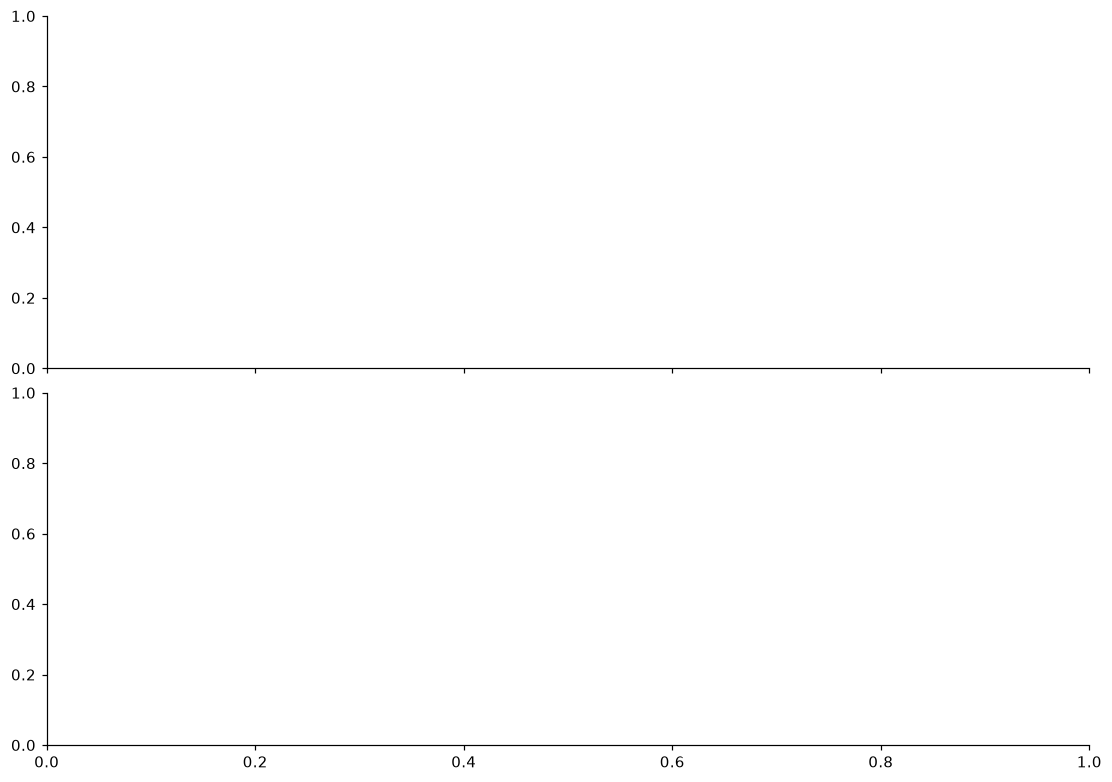

In [7]:
# Full ion spectrum has its own streamed pass, independent of electron coverage.
from collections import Counter
from ee_ion_covariance import iter_shots
ion_counters = []
for ds in datasets:
    hist = Counter()
    for block in iter_shots(ds, settings, load_ions=True):
        hits = block['ions'][block['valid']]
        hits = hits[np.isfinite(hits) & (hits > 0)]
        bins, counts = np.unique(np.floor(hits / ION_TOF_BIN_WIDTH).astype(np.int64), return_counts=True)
        hist.update(dict(zip(bins.tolist(), counts.tolist())))
    ion_counters.append(hist)
ion_total = sum(ion_counters, start=type(ion_counters[0])())
ion_edges, ion_sum = histogram_from_counter(ion_total, ION_TOF_BIN_WIDTH)
fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True, constrained_layout=True)
for ds, hist in zip(datasets, ion_counters):
    edges, counts = histogram_from_counter(hist, ION_TOF_BIN_WIDTH, (ion_edges[0], ion_edges[-1]))
    axes[0].stairs(counts, edges, label=f"{ds['hv']:.1f} eV")
axes[1].stairs(ion_sum, ion_edges, color='k', label="summed counts")
for ax in axes:
    for name, roi, colour in [('signal ROI (unassigned)', ION_SIGNAL_ROI, 'C3'), ('control ROI', ION_CONTROL_ROI, 'C2')]:
        if roi is not None: ax.axvspan(*roi, color=colour, alpha=.2, label=name)
    ax.set_ylabel("ion counts / TOF bin")
    ax.legend(fontsize=9, ncol=3)
if ION_TOF_PLOT_RANGE is not None: axes[1].set_xlim(ION_TOF_PLOT_RANGE)
axes[1].set_xlabel("ion TOF (100 ps)")
plt.show()
print("Ion gates:", ION_SIGNAL_ROI, ION_CONTROL_ROI, "(no physical assignments)")

## 3. Unique raw two-electron coincidence
Can correlated partners be detected before background subtraction? For each valid shot, form every distinct hit pair **i < j**, exclude padding zeros and place it once at `(faster KE, slower KE)`. This is a triangular **coincidence-count** histogram, including pairs of real hits within the same bin; it is not covariance. Multiplicity statistics and total raw pairs include all positive finite hits; plotted pairs additionally require calibration and map support. Report the difference explicitly.

Raw coincidence contains accidental pairs and common GMD modulation. Higher-multiplicity shots contribute `n(n−1)/2` pairs; saturated hit slots and detector dead time may distort yields. No smoothing is applied. Log colour affects display only.

274.0 eV: valid shots=2,665,662, >=1e=837,264, >=2e=311,174, total raw pairs=697,502, plotted pairs=431,393, lost pairs=266,109, filled slots=9, sum G=1.52049e+07, sum norm=1.52049e+07
274.5 eV: valid shots=3,332,152, >=1e=1,026,896, >=2e=377,139, total raw pairs=826,018, plotted pairs=520,425, lost pairs=305,593, filled slots=9, sum G=1.78915e+07, sum norm=1.78915e+07
275.0 eV: valid shots=3,342,892, >=1e=989,973, >=2e=353,144, total raw pairs=747,618, plotted pairs=477,334, lost pairs=270,284, filled slots=3, sum G=1.71078e+07, sum norm=1.71078e+07
275.5 eV: valid shots=3,332,439, >=1e=871,301, >=2e=296,460, total raw pairs=609,243, plotted pairs=391,866, lost pairs=217,377, filled slots=3, sum G=1.56099e+07, sum norm=1.56099e+07
276.0 eV: valid shots=3,332,025, >=1e=726,699, >=2e=235,397, total raw pairs=467,419, plotted pairs=303,886, lost pairs=163,533, filled slots=1, sum G=1.3616e+07, sum norm=1.3616e+07
276.5 eV: valid shots=5,382,593, >=1e=0, >=2e=0, total raw pairs=0, plotted

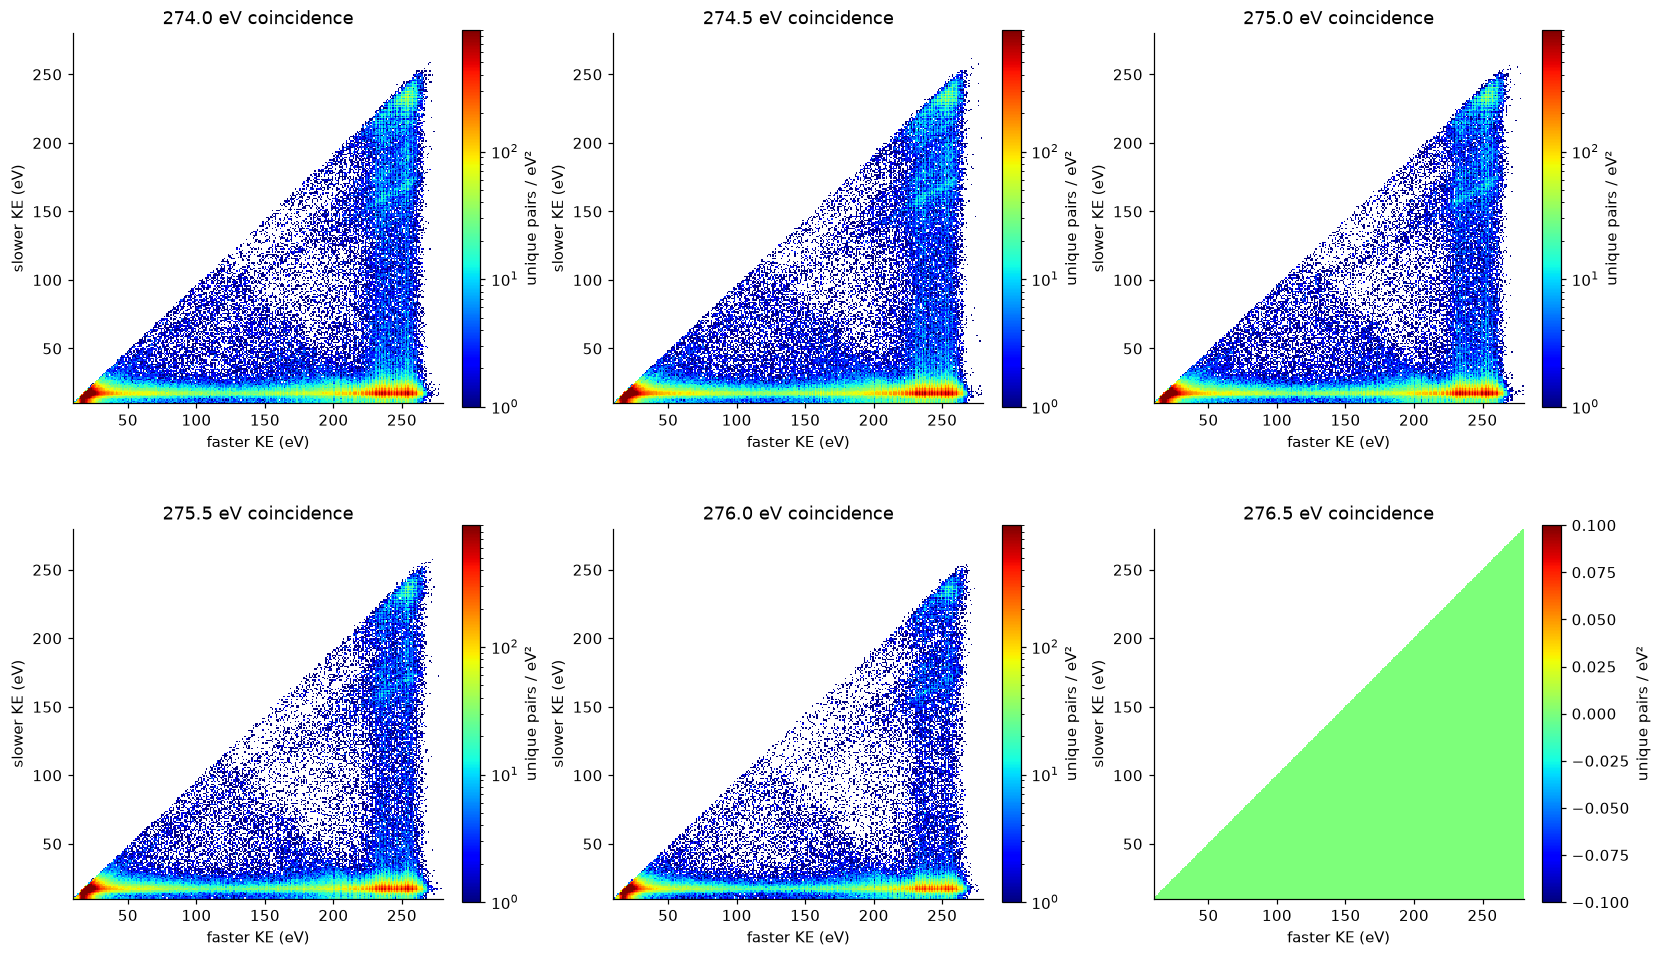

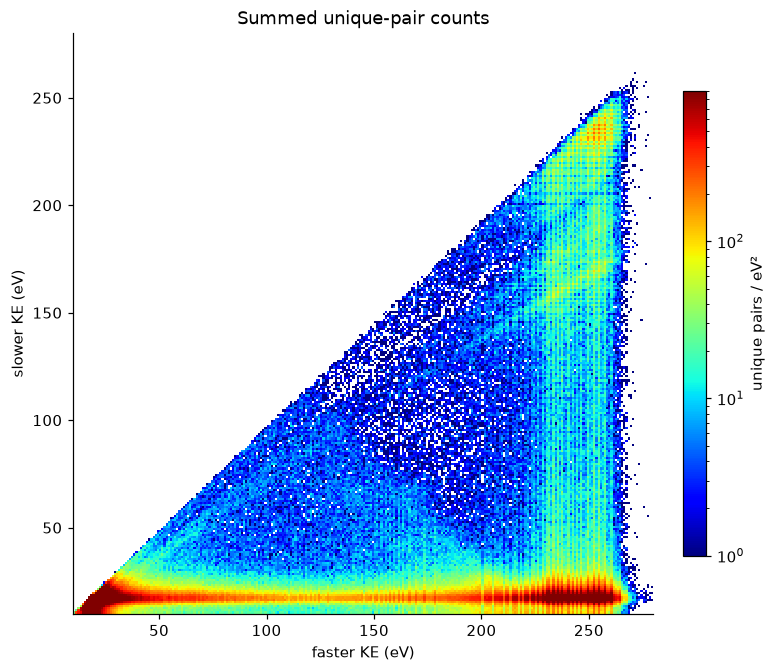

In [24]:
# Shared plotting helpers; axis order is rows=slow, columns=fast for coincidence.
def plot_map(ax, edges, matrix, title, covariance=False):
    widths = np.diff(edges)
    values = np.asarray(matrix, float) / (widths[:, None] * widths[None, :])
    if covariance:
        finite = np.abs(values[np.isfinite(values)])
        vmax = float(finite.max()) if finite.size and finite.max() > 0 else 1.0
        image = ax.pcolormesh(edges, edges, values, cmap='RdBu_r', vmin=-vmax, vmax=vmax, shading='flat')
    else:
        values = np.ma.masked_where(np.tril(np.ones(matrix.shape, bool), -1), values)
        positive = values.compressed(); positive = positive[positive > 0]
        norm = LogNorm(vmin=positive.min(), vmax=9e2) if COINCIDENCE_LOG and positive.size else None
        image = ax.pcolormesh(edges, edges, values, norm=norm, cmap='jet', shading='flat')
    ax.set(title=title, xlabel="faster KE (eV)" if not covariance else "electron KE j (eV)", ylabel="slower KE (eV)" if not covariance else "electron KE i (eV)")
    limits = KE_PLOT_RANGE if KE_PLOT_RANGE is not None else (ke_edges[0], ke_edges[-1])
    ax.set_xlim(limits); ax.set_ylim(limits)
    ax.set_aspect('equal', adjustable='box')
    plt.colorbar(image, ax=ax, label="covariance / eV²" if covariance else "unique pairs / eV²", shrink=.8)

def print_stats(label, r):
    print(f"{label}: valid shots={r['shots']:,}, >=1e={r['one']:,}, >=2e={r['two']:,}, total raw pairs={r['raw_pairs']:,}, plotted pairs={r['map_pairs']:,}, lost pairs={r['raw_pairs']-r['map_pairs']:,}, filled slots={r['filled']:,}, sum G={r['sum_gmd']:.6g}, sum norm={r['sum_norm']:.6g}")

fig, axes = plt.subplots(2, 3, figsize=(15, 9), constrained_layout=True)
for ax, (hv, r) in zip(axes.flat, raw.items()):
    print_stats(f"{hv:.1f} eV", r)
    plot_map(ax, ke_edges, r['pairs'], f"{hv:.1f} eV coincidence")
plt.show()
if SHOW_SUMMED:
    fig, ax = plt.subplots(figsize=(7, 6), constrained_layout=True)
    plot_map(ax, ke_edges, sum(r['pairs'] for r in raw.values()), "Summed unique-pair counts")
    plt.show()

274.0 eV | high-KE PE: PE KE=249.0-259.0 eV, PE singles=5,435, partner pairs=1,039
274.0 eV | low-KE PE: PE KE=230.0-240.0 eV, PE singles=5,100, partner pairs=975
274.5 eV | high-KE PE: PE KE=249.5-259.5 eV, PE singles=7,055, partner pairs=1,336
274.5 eV | low-KE PE: PE KE=230.5-240.5 eV, PE singles=6,486, partner pairs=1,297
275.0 eV | high-KE PE: PE KE=250.0-260.0 eV, PE singles=6,605, partner pairs=1,322
275.0 eV | low-KE PE: PE KE=231.0-241.0 eV, PE singles=6,857, partner pairs=1,424
275.5 eV | high-KE PE: PE KE=250.5-260.5 eV, PE singles=6,431, partner pairs=1,161
275.5 eV | low-KE PE: PE KE=231.5-241.5 eV, PE singles=6,343, partner pairs=1,209
276.0 eV | high-KE PE: PE KE=251.0-261.0 eV, PE singles=6,300, partner pairs=1,024
276.0 eV | low-KE PE: PE KE=232.0-242.0 eV, PE singles=5,738, partner pairs=924
276.5 eV: no plotted coincidence pairs


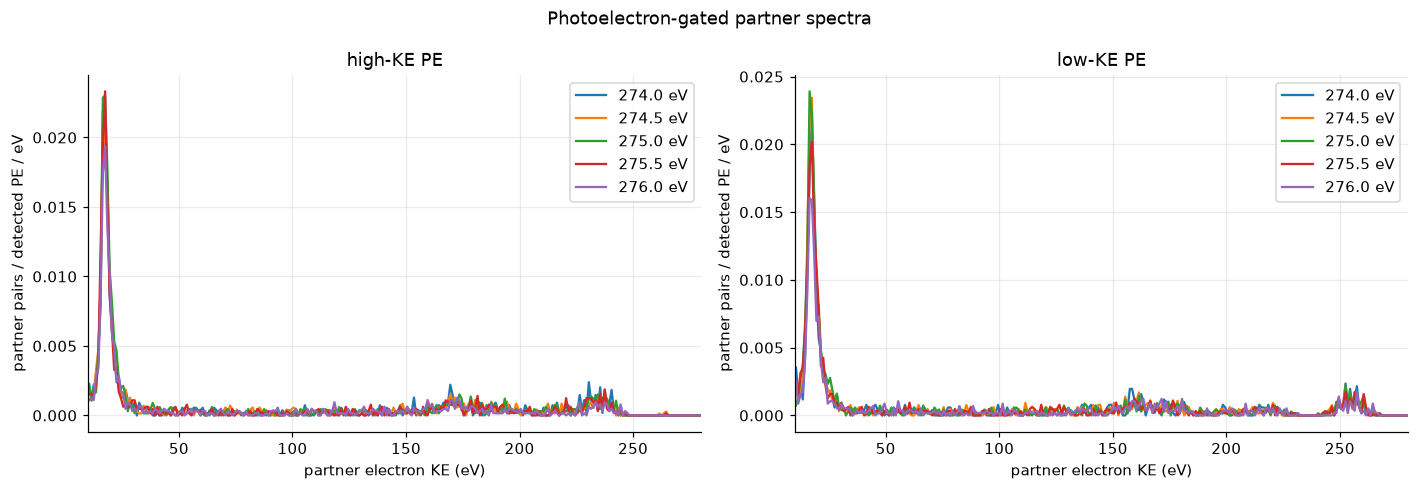

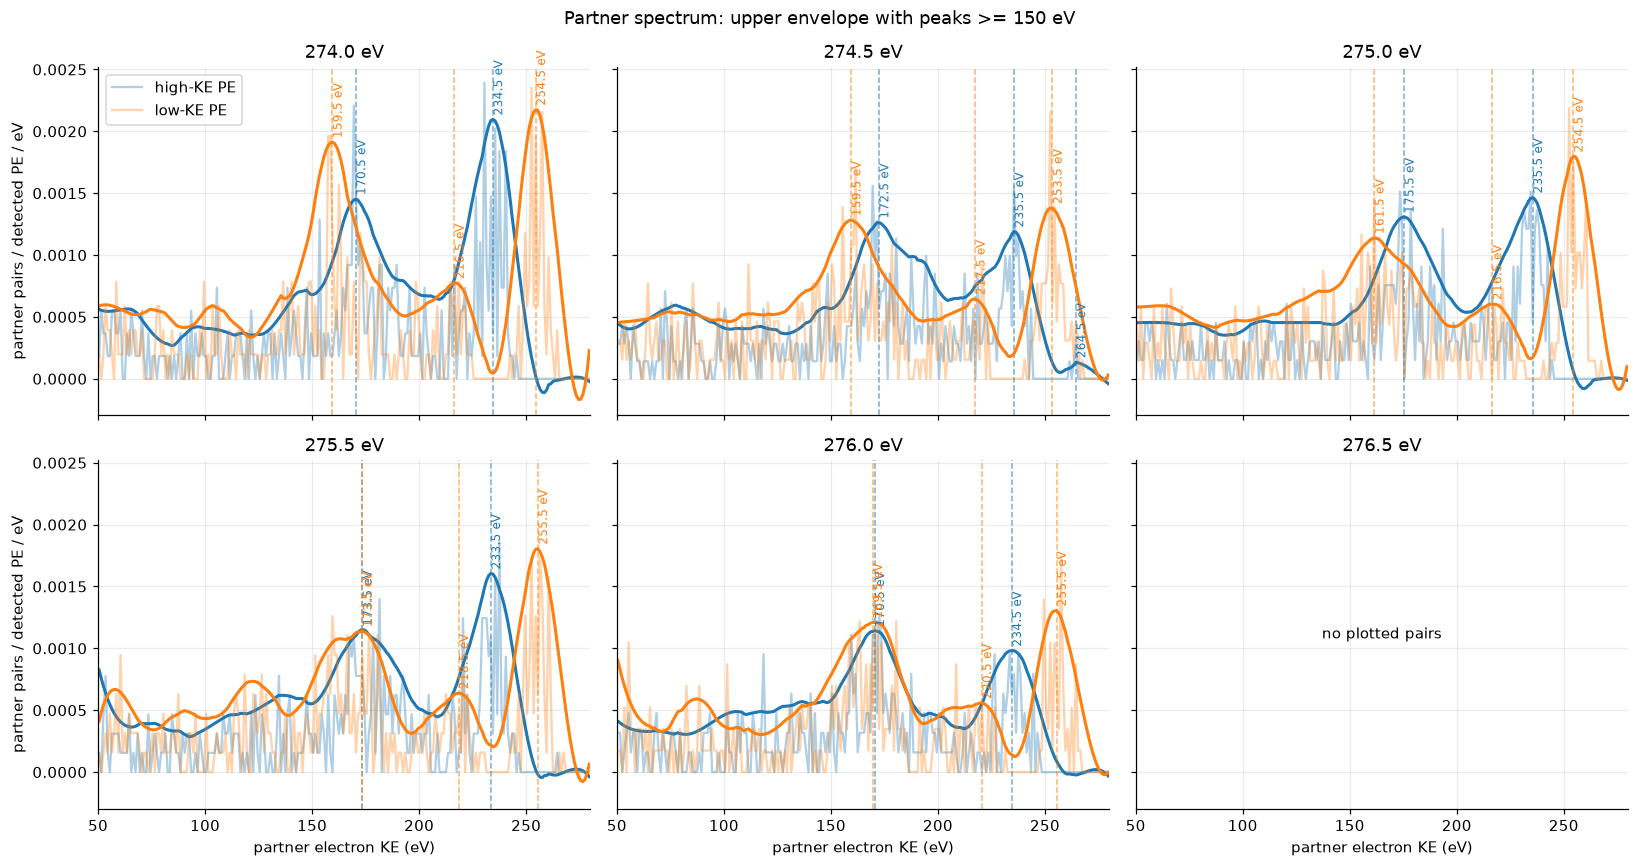

In [7]:
# --- Photoelectron-gated partner spectra -------------------------------------
# Gates are defined in binding energy so that the PE window follows hν.
PE_BE_WINDOWS = {
    "high-KE PE": (15.0, 25.0),  # 249-259 eV at hν=274 eV
    "low-KE PE": (34.0, 44.0),   # 230-240 eV at hν=274 eV
}

ke_centres = 0.5 * (ke_edges[:-1] + ke_edges[1:])
ke_widths = np.diff(ke_edges)

partner = {}
for hv in PHOTON_ENERGIES_EV:
    r = raw[hv]
    partner[hv] = {}

    if r["map_pairs"] == 0:
        print(f"{hv:.1f} eV: no plotted coincidence pairs")
        continue

    for label, be_window in PE_BE_WINDOWS.items():
        counts, ke_window, idx = coincidence_projection(r["pairs"], ke_edges, hv, be_window)
        n_pe = int(r["single"][idx].sum())
        per_gmd = counts / (r["sum_norm"] * ke_widths) if r["sum_norm"] > 0 else np.full_like(counts, np.nan, dtype=float)
        per_pe = counts / (n_pe * ke_widths) if n_pe > 0 else np.full_like(counts, np.nan, dtype=float)
        partner[hv][label] = dict(counts=counts, per_gmd=per_gmd, per_pe=per_pe, ke_window=ke_window, n_pe=n_pe)

        print(f"{hv:.1f} eV | {label}: PE KE={ke_window[0]:.1f}-{ke_window[1]:.1f} eV, PE singles={n_pe:,}, partner pairs={int(counts.sum()):,}")


# --- 1-2. Partner spectrum across photon energy for each PE gate -------------
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharex=True)

for ax, (label, _) in zip(axes, PE_BE_WINDOWS.items()):
    for hv in PHOTON_ENERGIES_EV:
        if label not in partner.get(hv, {}): continue
        ax.plot(ke_centres, partner[hv][label]["per_pe"], label=f"{hv:.1f} eV")

    ax.set_title(label)
    ax.set_xlabel("partner electron KE (eV)")
    ax.set_ylabel("partner pairs / detected PE / eV")
    ax.set_xlim(KE_ANALYSIS_RANGE)
    ax.grid(alpha=0.25)
    ax.legend()

fig.suptitle("Photoelectron-gated partner spectra")
fig.tight_layout()
plt.show()


# --- 3. Direct comparison of the two PE gates at each photon energy ----------
import numpy as np
from scipy.ndimage import percentile_filter
from scipy.signal import find_peaks, savgol_filter

# 1. Filter to region >= 50 eV
mask_50 = ke_centres >= 50.0
x_smooth = ke_centres[mask_50]

fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharex=True, sharey=True)
axes = axes.ravel()

for ax, hv in zip(axes, PHOTON_ENERGIES_EV):
    if raw[hv]["map_pairs"] == 0:
        ax.text(0.5, 0.5, "no plotted pairs", ha="center", va="center", transform=ax.transAxes)
    else:
        for label in PE_BE_WINDOWS:
            if label not in partner[hv]: continue
            y = partner[hv][label]["per_pe"][mask_50]
            
            # Plot raw data
            p = ax.plot(x_smooth, y, alpha=0.35, label=label)
            color = p[0].get_color()

            # 2. Extract upper envelope and smooth
            envelope = percentile_filter(y, percentile=90, size=15)
            y_smooth = savgol_filter(envelope, window_length=31, polyorder=3)

            # Plot smoothed upper boundary line
            ax.plot(x_smooth, y_smooth, color=color, linewidth=2.0)

            # 3. Find all local peaks on the smoothed curve above 150 eV
            peaks, _ = find_peaks(y_smooth, distance=15, prominence=np.ptp(y_smooth) * 0.05)
            
            for p_idx in peaks:
                peak_x = x_smooth[p_idx]
                
                if peak_x >= 150.0:
                    peak_y = y_smooth[p_idx]

                    # Draw vertical line
                    ax.axvline(peak_x, color=color, linestyle="--", alpha=0.6, linewidth=1.0)

                    # Add vertical text next to the line
                    ax.text(
                        peak_x,
                        peak_y,
                        f" {peak_x:.1f} eV",
                        rotation=90,
                        verticalalignment="bottom",
                        horizontalalignment="left",
                        fontsize=8,
                        color=color,
                    )

    ax.set_title(f"{hv:.1f} eV")
    ax.set_xlim(50.0, KE_ANALYSIS_RANGE[1])
    ax.grid(alpha=0.25)

for ax in axes[3:]:
    ax.set_xlabel("partner electron KE (eV)")
for ax in axes[::3]:
    ax.set_ylabel("partner pairs / detected PE / eV")

axes[0].legend()
fig.suptitle("Partner spectrum: upper envelope with peaks >= 150 eV")
fig.tight_layout()
plt.show()

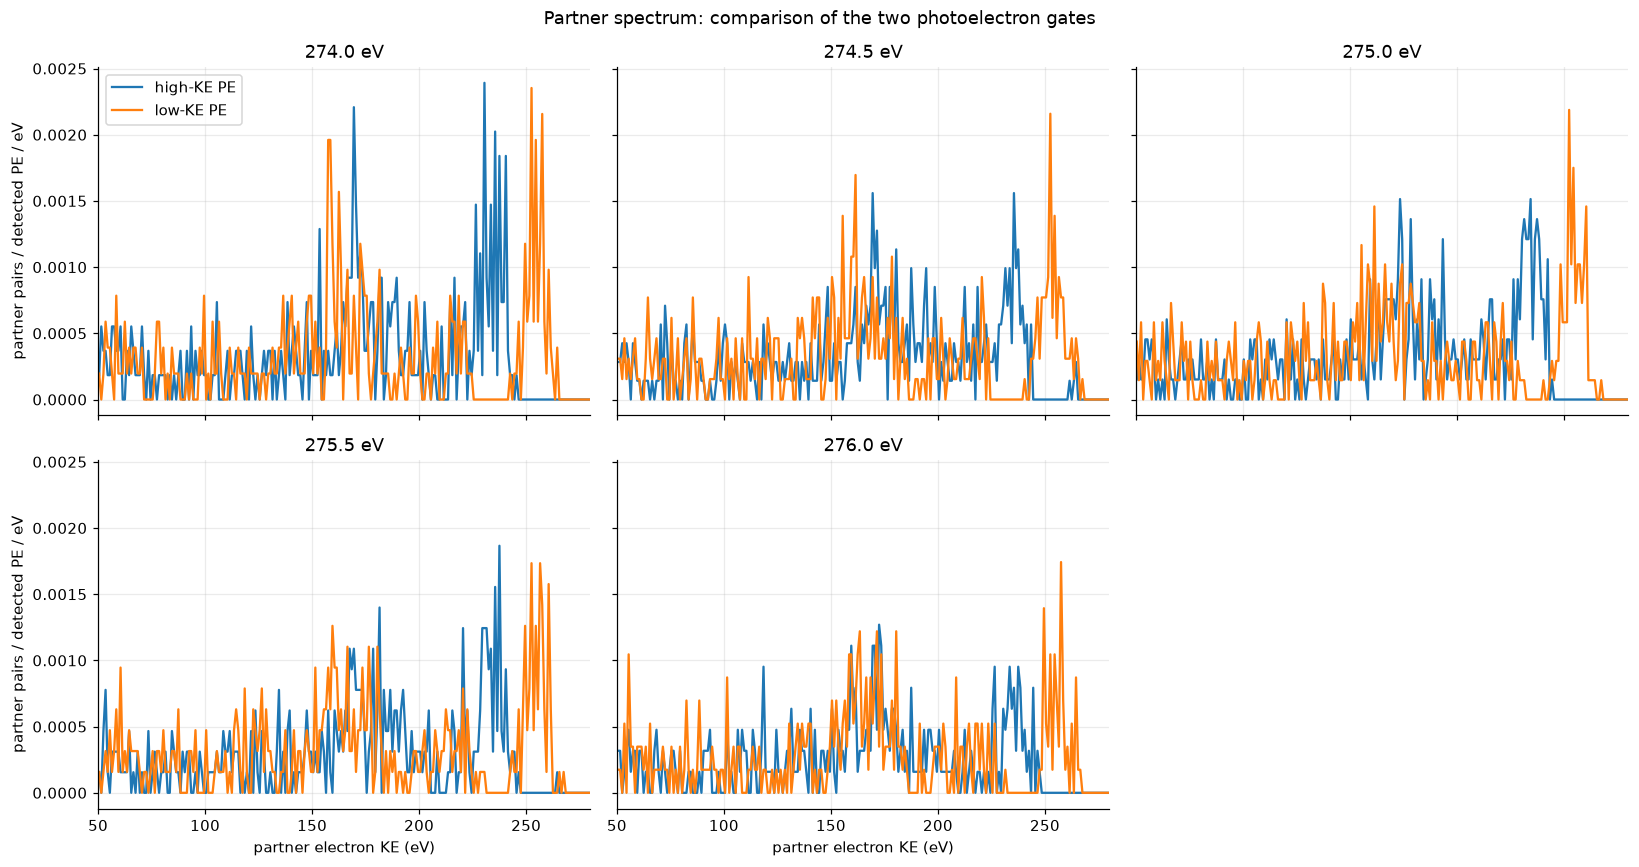

In [36]:
# --- 3. Direct comparison of the two PE gates at each photon energy ----------
fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharex=True, sharey=True)
axes = axes.ravel()

ke_mask = ke_centres >= 50.0

for ax, hv in zip(axes[:5], PHOTON_ENERGIES_EV[:5]):
    if raw[hv]["map_pairs"] == 0:
        ax.text(0.5, 0.5, "no plotted pairs", ha="center", va="center", transform=ax.transAxes)
    else:
        for label in PE_BE_WINDOWS:
            if label not in partner[hv]: continue
            y = partner[hv][label]["per_pe"]
            ax.plot(ke_centres[ke_mask], y[ke_mask], label=label)

    ax.set_title(f"{hv:.1f} eV")
    ax.set_xlim(50.0, KE_ANALYSIS_RANGE[1])
    ax.grid(alpha=0.25)

fig.delaxes(axes[5])

for ax in [axes[3], axes[4]]:
    ax.set_xlabel("partner electron KE (eV)")
for ax in axes[::3]:
    ax.set_ylabel("partner pairs / detected PE / eV")

axes[0].legend()
fig.suptitle("Partner spectrum: comparison of the two photoelectron gates")
fig.tight_layout()
plt.show()

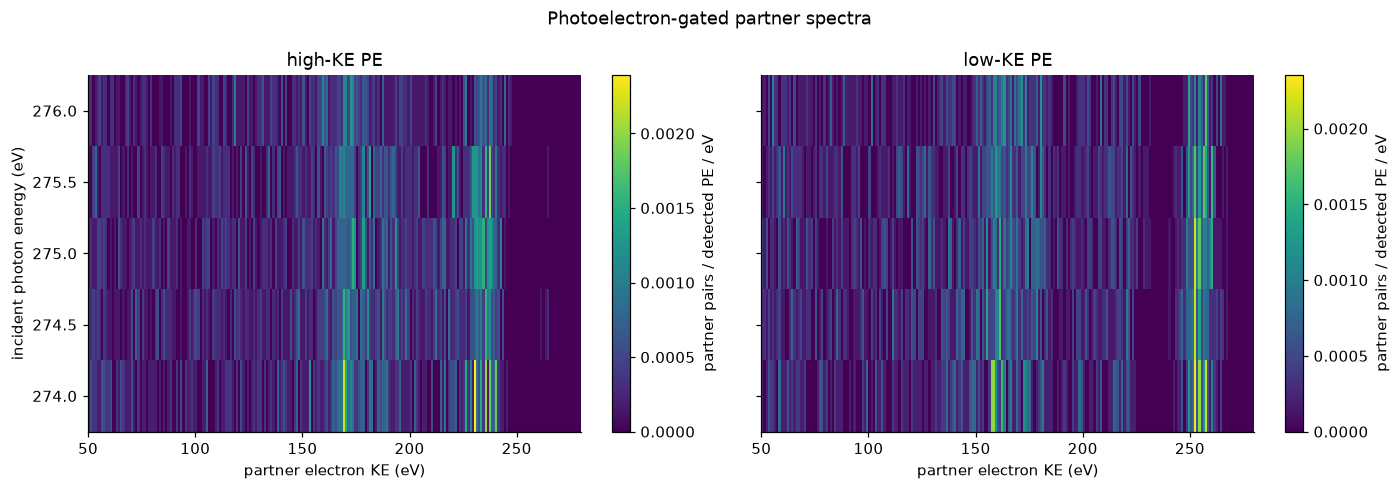

In [14]:
# --- PE-gated partner spectra as incident-energy maps ------------------------
energies = np.array([hv for hv in PHOTON_ENERGIES_EV if raw[hv]["map_pairs"] > 0])
ke_centres = 0.5 * (ke_edges[:-1] + ke_edges[1:])
ke_mask = ke_centres >= 50.0

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharex=True, sharey=True)

for ax, label in zip(axes, PE_BE_WINDOWS):
    z = np.array([partner[hv][label]["per_pe"] for hv in energies])
    z_sub = z[:, ke_mask]
    vmin, vmax = np.nanmin(z_sub), np.nanmax(z_sub)

    mesh = ax.pcolormesh(
        ke_edges,
        np.r_[energies - 0.25, energies[-1] + 0.25],
        z,
        shading="flat",
        vmin=vmin,
        vmax=vmax,
    )

    fig.colorbar(mesh, ax=ax, label="partner pairs / detected PE / eV")
    ax.set_title(label)
    ax.set_xlabel("partner electron KE (eV)")

axes[0].set_xlim(50.0, KE_ANALYSIS_RANGE[1])
axes[0].set_ylabel("incident photon energy (eV)")
fig.suptitle("Photoelectron-gated partner spectra")
fig.tight_layout()
plt.show()

In [22]:
# --- Fixed-window test for the ~216-220 eV candidate -------------------------
CANDIDATE_WINDOW = (210.0, 225.0)
CONTROL_WINDOWS = [(195.0, 210.0), (225.0, 230.0)]

def window_stats(x, y, window):
    m = (x >= window[0]) & (x < window[1]) & np.isfinite(y)
    if not np.any(m): return np.nan, np.nan, np.nan
    integral = np.sum(y[m] * ke_widths[m])
    mean_density = integral / np.sum(ke_widths[m])
    centroid = np.sum(x[m] * y[m] * ke_widths[m]) / integral if integral > 0 else np.nan
    return integral, mean_density, centroid

candidate_stats = {}

for label in PE_BE_WINDOWS:
    candidate_stats[label] = []
    print(f"\n{label}")

    for hv in PHOTON_ENERGIES_EV:
        if label not in partner.get(hv, {}): continue

        y = partner[hv][label]["per_pe"]# --- Fixed-window test for the ~216-220 eV candidate -------------------------
CANDIDATE_WINDOW = (210.0, 225.0)
CONTROL_WINDOWS = [(195.0, 210.0), (225.0, 230.0)]

def window_stats(x, y, window):
    m = (x >= window[0]) & (x < window[1]) & np.isfinite(y)
    if not np.any(m): return np.nan, np.nan, np.nan
    integral = np.sum(y[m] * ke_widths[m])
    mean_density = integral / np.sum(ke_widths[m])
    centroid = np.sum(x[m] * y[m] * ke_widths[m]) / integral if integral > 0 else np.nan
    return integral, mean_density, centroid

candidate_stats = {}

for label in PE_BE_WINDOWS:
    candidate_stats[label] = []
    print(f"\n{label}")

    for hv in PHOTON_ENERGIES_EV:
        if label not in partner.get(hv, {}): continue

        y = partner[hv][label]["per_pe"]
        cand_int, cand_density, centroid_ke = window_stats(ke_centres, y, CANDIDATE_WINDOW)

        control_density = []
        for window in CONTROL_WINDOWS:
            _, density, _ = window_stats(ke_centres, y, window)
            control_density.append(density)

        control_mean = np.nanmean(control_density)
        excess = cand_density - control_mean
        centroid_be = hv - centroid_ke if np.isfinite(centroid_ke) else np.nan

        candidate_stats[label].append(dict(
            hv=hv, candidate_integral=cand_int, candidate_density=cand_density,
            control_density=control_mean, excess=excess,
            centroid_ke=centroid_ke, centroid_be=centroid_be
        ))

        print(f"{hv:.1f} eV | candidate={cand_density:.6g}/eV | control={control_mean:.6g}/eV | "
              f"excess={excess:.6g}/eV | centroid KE={centroid_ke:.2f} eV | BE={centroid_be:.2f} eV")
        cand_int, cand_density, centroid_ke = window_stats(ke_centres, y, CANDIDATE_WINDOW)

        control_density = []
        for window in CONTROL_WINDOWS:
            _, density, _ = window_stats(ke_centres, y, window)
            control_density.append(density)

        control_mean = np.nanmean(control_density)
        excess = cand_density - control_mean
        centroid_be = hv - centroid_ke if np.isfinite(centroid_ke) else np.nan

        candidate_stats[label].append(dict(
            hv=hv, candidate_integral=cand_int, candidate_density=cand_density,
            control_density=control_mean, excess=excess,
            centroid_ke=centroid_ke, centroid_be=centroid_be
        ))

        print(f"{hv:.1f} eV | candidate={cand_density:.6g}/eV | control={control_mean:.6g}/eV | "
              f"excess={excess:.6g}/eV | centroid KE={centroid_ke:.2f} eV | BE={centroid_be:.2f} eV")


high-KE PE

low-KE PE

high-KE PE
274.0 eV | candidate=0.000343453/eV | control=0.000466115/eV | excess=-0.000122662/eV | centroid KE=217.93 eV | BE=56.07 eV
274.0 eV | candidate=0.000343453/eV | control=0.000466115/eV | excess=-0.000122662/eV | centroid KE=217.93 eV | BE=56.07 eV
274.5 eV | candidate=0.000387432/eV | control=0.000354359/eV | excess=3.30735e-05/eV | centroid KE=217.40 eV | BE=57.10 eV
274.5 eV | candidate=0.000387432/eV | control=0.000354359/eV | excess=3.30735e-05/eV | centroid KE=217.40 eV | BE=57.10 eV
275.0 eV | candidate=0.000383548/eV | control=0.000434015/eV | excess=-5.04668e-05/eV | centroid KE=217.00 eV | BE=58.00 eV
275.0 eV | candidate=0.000383548/eV | control=0.000434015/eV | excess=-5.04668e-05/eV | centroid KE=217.00 eV | BE=58.00 eV
275.5 eV | candidate=0.000269528/eV | control=0.000393925/eV | excess=-0.000124397/eV | centroid KE=219.15 eV | BE=56.35 eV
275.5 eV | candidate=0.000269528/eV | control=0.000393925/eV | excess=-0.000124397/eV | centroid KE

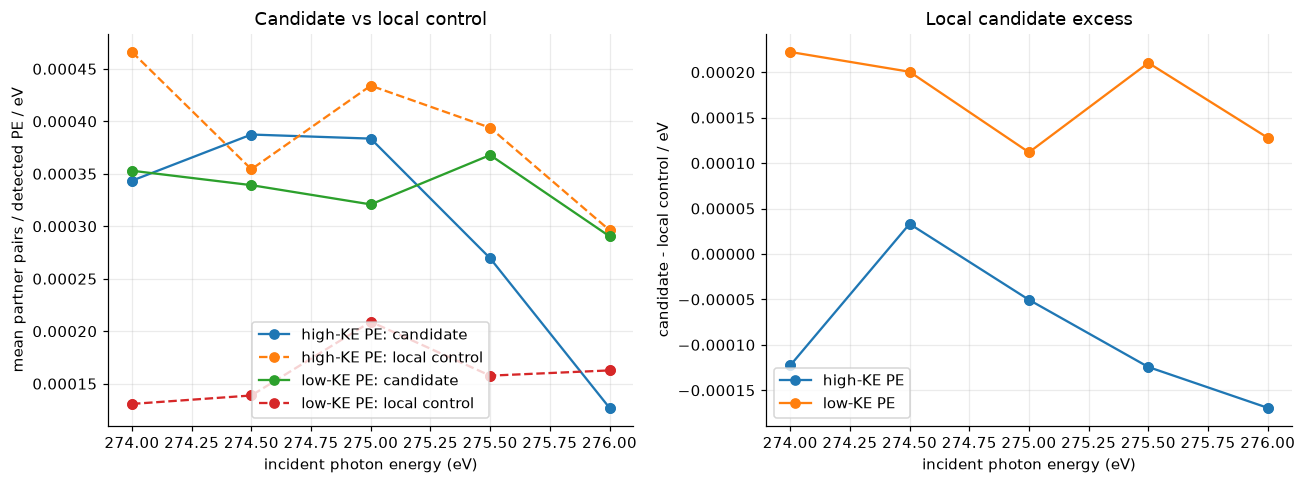

In [23]:
# --- Candidate-window strength across photon energy --------------------------
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharex=True)

for label in PE_BE_WINDOWS:
    s = candidate_stats[label]
    hv = np.array([r["hv"] for r in s])
    candidate = np.array([r["candidate_density"] for r in s])
    control = np.array([r["control_density"] for r in s])
    excess = np.array([r["excess"] for r in s])

    axes[0].plot(hv, candidate, "o-", label=f"{label}: candidate")
    axes[0].plot(hv, control, "o--", label=f"{label}: local control")
    axes[1].plot(hv, excess, "o-", label=label)

axes[0].set_ylabel("mean partner pairs / detected PE / eV")
axes[0].set_title("Candidate vs local control")
axes[1].set_ylabel("candidate - local control / eV")
axes[1].set_title("Local candidate excess")

for ax in axes:
    ax.set_xlabel("incident photon energy (eV)")
    ax.grid(alpha=0.25)
    ax.legend()

fig.tight_layout()
plt.show()

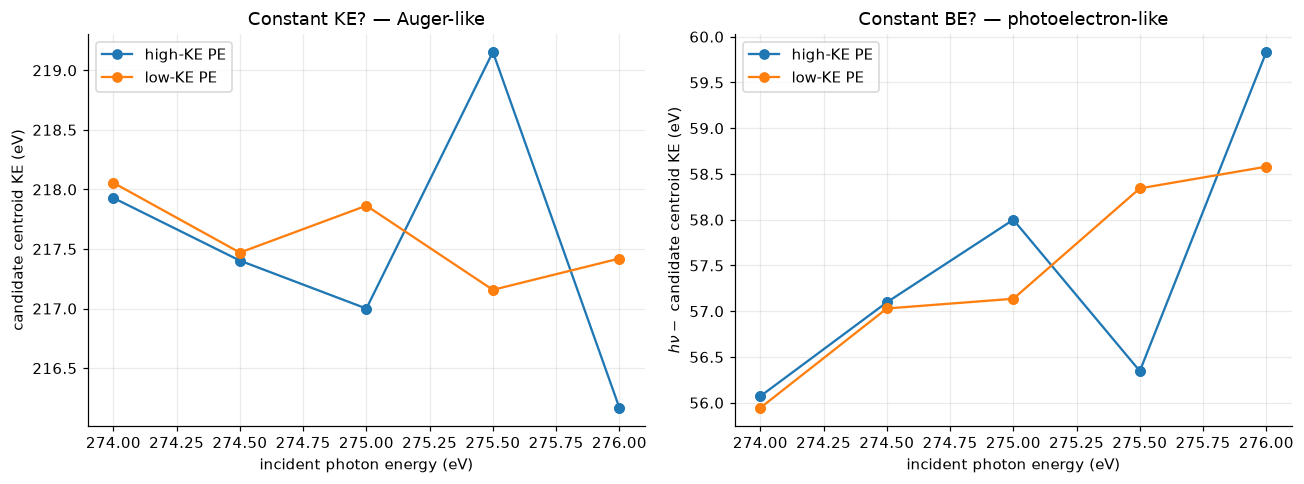

In [24]:
# --- Does the candidate stay fixed in KE or in BE? ---------------------------
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharex=True)

for label in PE_BE_WINDOWS:
    s = candidate_stats[label]
    hv = np.array([r["hv"] for r in s])
    centroid_ke = np.array([r["centroid_ke"] for r in s])
    centroid_be = np.array([r["centroid_be"] for r in s])

    axes[0].plot(hv, centroid_ke, "o-", label=label)
    axes[1].plot(hv, centroid_be, "o-", label=label)

axes[0].set_ylabel("candidate centroid KE (eV)")
axes[0].set_title("Constant KE? — Auger-like")
axes[1].set_ylabel(r"$h\nu -$ candidate centroid KE (eV)")
axes[1].set_title("Constant BE? — photoelectron-like")

for ax in axes:
    ax.set_xlabel("incident photon energy (eV)")
    ax.grid(alpha=0.25)
    ax.legend()

fig.tight_layout()
plt.show()

In [26]:
# --- Local sideband baseline and background-subtracted candidate centroid ----
CANDIDATE_WINDOW = (210.0, 225.0)
SIDEBANDS = [(195.0, 210.0), (225.0, 230.0)]

def weighted_mean(x, y, w, mask):
    return np.sum(y[mask] * w[mask]) / np.sum(w[mask])

def local_candidate_stats(x, y, widths):
    mc = (x >= CANDIDATE_WINDOW[0]) & (x < CANDIDATE_WINDOW[1])
    m1 = (x >= SIDEBANDS[0][0]) & (x < SIDEBANDS[0][1])
    m2 = (x >= SIDEBANDS[1][0]) & (x < SIDEBANDS[1][1])

    x1 = np.sum(x[m1] * widths[m1]) / np.sum(widths[m1])
    x2 = np.sum(x[m2] * widths[m2]) / np.sum(widths[m2])
    y1 = weighted_mean(x, y, widths, m1)
    y2 = weighted_mean(x, y, widths, m2)

    slope = (y2 - y1) / (x2 - x1)
    baseline = y1 + slope * (x - x1)

    cand_mean = weighted_mean(x, y, widths, mc)
    base_mean = weighted_mean(x, baseline, widths, mc)
    residual = y - baseline
    positive = np.clip(residual, 0, None)

    signed_excess = np.sum(residual[mc] * widths[mc])
    positive_excess = np.sum(positive[mc] * widths[mc])
    centroid = np.sum(x[mc] * positive[mc] * widths[mc]) / positive_excess if positive_excess > 0 else np.nan

    return dict(baseline=baseline, residual=residual, candidate_mean=cand_mean, baseline_mean=base_mean,
                excess_mean=cand_mean - base_mean, signed_excess=signed_excess,
                positive_excess=positive_excess, centroid_ke=centroid)

candidate_bg = {}

for label in PE_BE_WINDOWS:
    candidate_bg[label] = []

    print(f"\n{label}")
    for hv in PHOTON_ENERGIES_EV:
        if label not in partner.get(hv, {}): continue

        y = partner[hv][label]["per_pe"]
        s = local_candidate_stats(ke_centres, y, ke_widths)
        s["hv"] = hv
        s["centroid_be"] = hv - s["centroid_ke"] if np.isfinite(s["centroid_ke"]) else np.nan
        candidate_bg[label].append(s)

        print(f"{hv:.1f} eV | candidate={s['candidate_mean']:.6g} | baseline={s['baseline_mean']:.6g} | "
              f"excess={s['excess_mean']:.6g} | centroid KE={s['centroid_ke']:.2f} eV | "
              f"BE={s['centroid_be']:.2f} eV")


high-KE PE
274.0 eV | candidate=0.000343453 | baseline=0.000512726 | excess=-0.000169273 | centroid KE=215.69 eV | BE=58.31 eV
274.5 eV | candidate=0.000387432 | baseline=0.000362863 | excess=2.45689e-05 | centroid KE=216.35 eV | BE=58.15 eV
275.0 eV | candidate=0.000383548 | baseline=0.000462276 | excess=-7.87282e-05 | centroid KE=214.72 eV | BE=60.28 eV
275.5 eV | candidate=0.000269528 | baseline=0.000427098 | excess=-0.00015757 | centroid KE=219.60 eV | BE=55.90 eV
276.0 eV | candidate=0.000126984 | baseline=0.000306878 | excess=-0.000179894 | centroid KE=212.77 eV | BE=63.23 eV

low-KE PE
274.0 eV | candidate=0.000352941 | baseline=0.000104575 | excess=0.000248366 | centroid KE=218.39 eV | BE=55.61 eV
274.5 eV | candidate=0.000339192 | baseline=0.000111008 | excess=0.000228184 | centroid KE=218.46 eV | BE=56.04 eV
275.0 eV | candidate=0.00032084 | baseline=0.000202226 | excess=0.000118614 | centroid KE=217.95 eV | BE=57.05 eV
275.5 eV | candidate=0.00036786 | baseline=0.000145042 

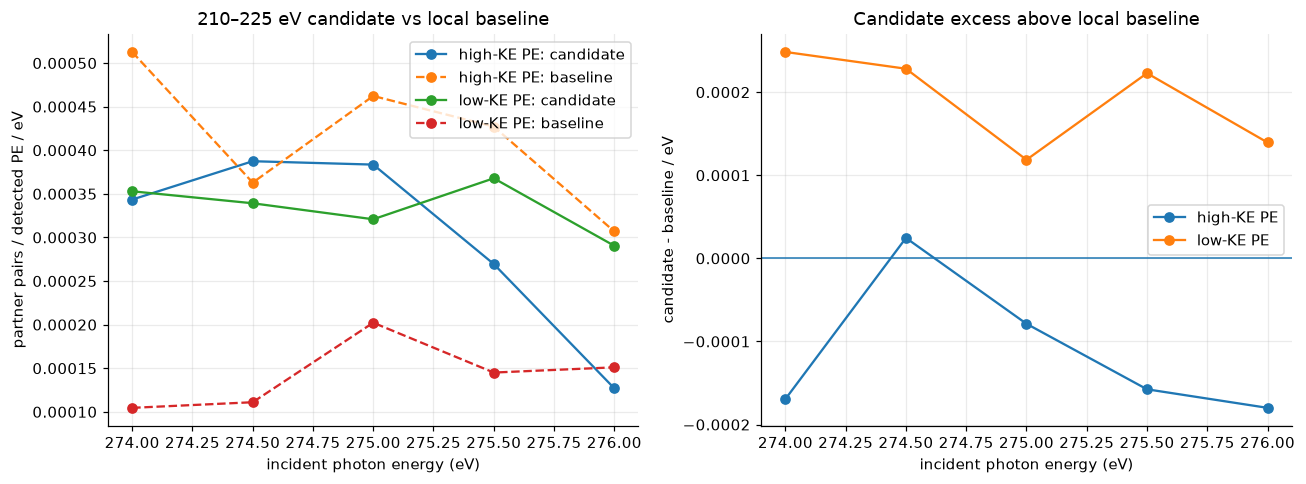

In [27]:
# --- Candidate level compared with the local sideband baseline ---------------
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharex=True)

for label in PE_BE_WINDOWS:
    s = candidate_bg[label]
    hv = np.array([r["hv"] for r in s])
    candidate = np.array([r["candidate_mean"] for r in s])
    baseline = np.array([r["baseline_mean"] for r in s])
    excess = np.array([r["excess_mean"] for r in s])

    axes[0].plot(hv, candidate, "o-", label=f"{label}: candidate")
    axes[0].plot(hv, baseline, "o--", label=f"{label}: baseline")
    axes[1].plot(hv, excess, "o-", label=label)

axes[0].set_title("210–225 eV candidate vs local baseline")
axes[0].set_ylabel("partner pairs / detected PE / eV")
axes[1].axhline(0, linewidth=1)
axes[1].set_title("Candidate excess above local baseline")
axes[1].set_ylabel("candidate - baseline / eV")

for ax in axes:
    ax.set_xlabel("incident photon energy (eV)")
    ax.grid(alpha=0.25)
    ax.legend()

fig.tight_layout()
plt.show()

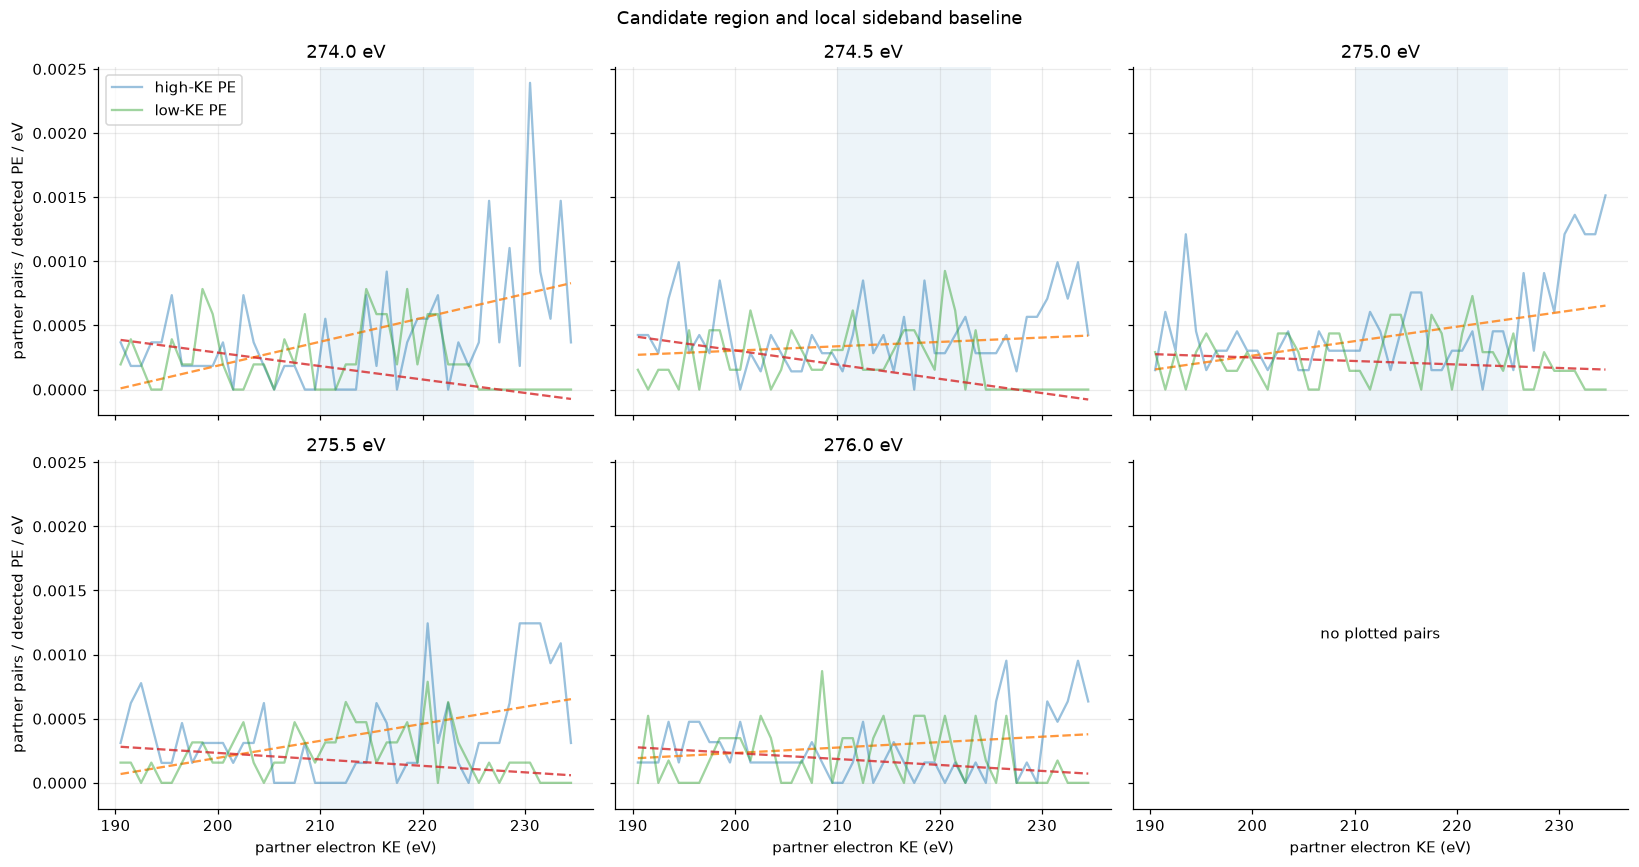

In [28]:
# --- Local continuum subtraction around the candidate ------------------------
fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharex=True, sharey=True)
axes = axes.ravel()
PLOT_RANGE = (190.0, 235.0)
mp = (ke_centres >= PLOT_RANGE[0]) & (ke_centres <= PLOT_RANGE[1])

for ax, hv in zip(axes, PHOTON_ENERGIES_EV):
    if raw[hv]["map_pairs"] == 0:
        ax.text(0.5, 0.5, "no plotted pairs", ha="center", va="center", transform=ax.transAxes)
        continue

    for label in PE_BE_WINDOWS:
        if label not in partner.get(hv, {}): continue
        y = partner[hv][label]["per_pe"]
        s = next(r for r in candidate_bg[label] if r["hv"] == hv)

        ax.plot(ke_centres[mp], y[mp], alpha=0.45, label=label)
        ax.plot(ke_centres[mp], s["baseline"][mp], "--", alpha=0.8)

    ax.axvspan(*CANDIDATE_WINDOW, alpha=0.08)
    ax.set_title(f"{hv:.1f} eV")
    ax.grid(alpha=0.25)

for ax in axes[3:]:
    ax.set_xlabel("partner electron KE (eV)")
for ax in axes[::3]:
    ax.set_ylabel("partner pairs / detected PE / eV")

axes[0].legend()
fig.suptitle("Candidate region and local sideband baseline")
fig.tight_layout()
plt.show()

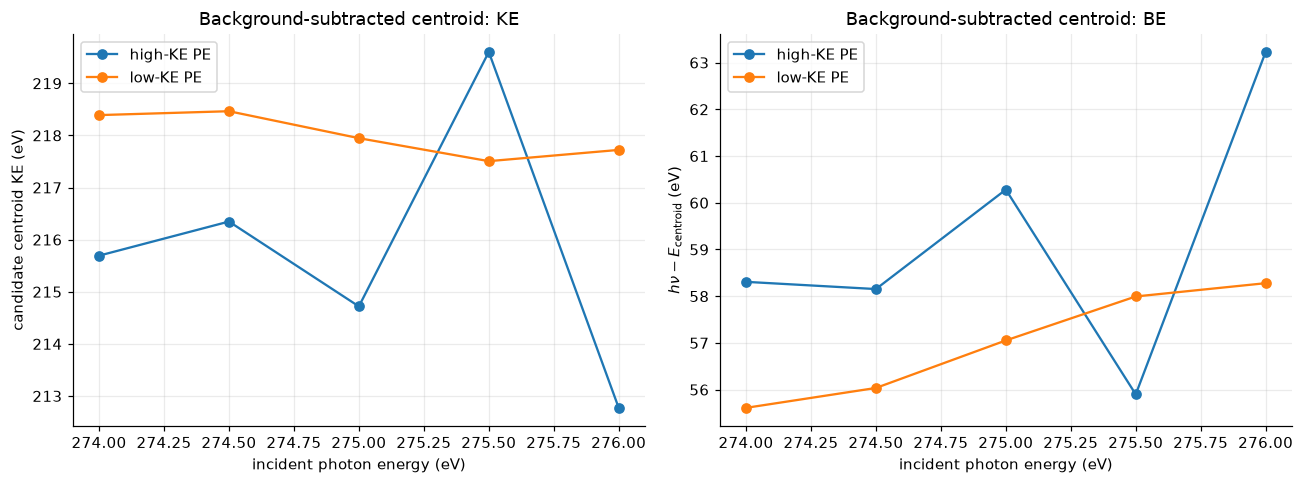

In [29]:
# --- Background-subtracted centroid test ------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharex=True)

for label in PE_BE_WINDOWS:
    s = candidate_bg[label]
    hv = np.array([r["hv"] for r in s])
    centroid_ke = np.array([r["centroid_ke"] for r in s])
    centroid_be = np.array([r["centroid_be"] for r in s])

    axes[0].plot(hv, centroid_ke, "o-", label=label)
    axes[1].plot(hv, centroid_be, "o-", label=label)

axes[0].set_title("Background-subtracted centroid: KE")
axes[0].set_ylabel("candidate centroid KE (eV)")
axes[1].set_title("Background-subtracted centroid: BE")
axes[1].set_ylabel(r"$h\nu - E_{\rm centroid}$ (eV)")

for ax in axes:
    ax.set_xlabel("incident photon energy (eV)")
    ax.grid(alpha=0.25)
    ax.legend()

fig.tight_layout()
plt.show()

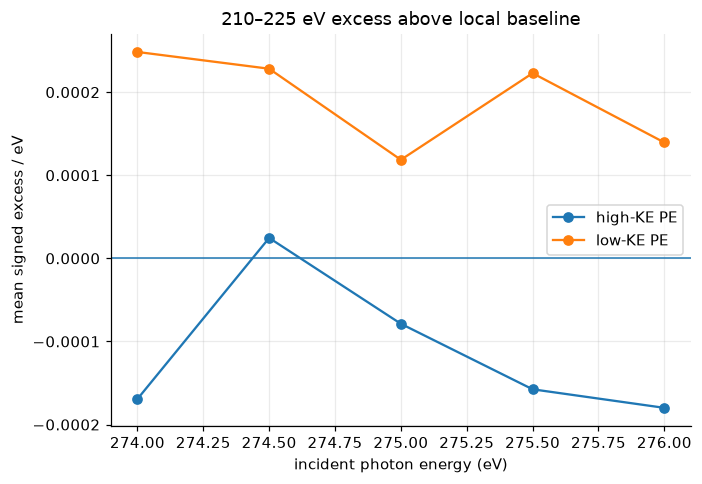

In [31]:
# --- Signed candidate excess above local baseline ----------------------------
fig, ax = plt.subplots(figsize=(6.5, 4.5))

for label in PE_BE_WINDOWS:
    s = candidate_bg[label]
    hv = np.array([r["hv"] for r in s])
    excess = np.array([r["signed_excess"] for r in s]) / (CANDIDATE_WINDOW[1] - CANDIDATE_WINDOW[0])
    ax.plot(hv, excess, "o-", label=label)

ax.axhline(0, linewidth=1)
ax.set_xlabel("incident photon energy (eV)")
ax.set_ylabel("mean signed excess / eV")
ax.set_title("210–225 eV excess above local baseline")
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
plt.show()

In [32]:
# --- Signed-residual centroid -------------------------------------------------
signed_centroids = {}

for label in PE_BE_WINDOWS:
    signed_centroids[label] = []

    for r in candidate_bg[label]:
        hv = r["hv"]
        y = partner[hv][label]["per_pe"]
        residual = y - r["baseline"]
        m = (ke_centres >= CANDIDATE_WINDOW[0]) & (ke_centres < CANDIDATE_WINDOW[1])

        area = np.sum(residual[m] * ke_widths[m])
        centroid_ke = np.sum(ke_centres[m] * residual[m] * ke_widths[m]) / area if area > 0 else np.nan
        centroid_be = hv - centroid_ke if np.isfinite(centroid_ke) else np.nan

        signed_centroids[label].append((hv, area, centroid_ke, centroid_be))
        print(f"{label:10s} | {hv:.1f} eV | excess={area:.6g} | KE={centroid_ke:.2f} eV | BE={centroid_be:.2f} eV")

high-KE PE | 274.0 eV | excess=-0.0025391 | KE=nan eV | BE=nan eV
high-KE PE | 274.5 eV | excess=0.000368533 | KE=213.38 eV | BE=61.12 eV
high-KE PE | 275.0 eV | excess=-0.00118092 | KE=nan eV | BE=nan eV
high-KE PE | 275.5 eV | excess=-0.00236355 | KE=nan eV | BE=nan eV
high-KE PE | 276.0 eV | excess=-0.00269841 | KE=nan eV | BE=nan eV
low-KE PE  | 274.0 eV | excess=0.00372549 | KE=219.08 eV | BE=54.92 eV
low-KE PE  | 274.5 eV | excess=0.00342276 | KE=218.36 eV | BE=56.14 eV
low-KE PE  | 275.0 eV | excess=0.0017792 | KE=218.91 eV | BE=56.09 eV
low-KE PE  | 275.5 eV | excess=0.00334227 | KE=217.36 eV | BE=58.14 eV
low-KE PE  | 276.0 eV | excess=0.00209132 | KE=217.96 eV | BE=58.04 eV


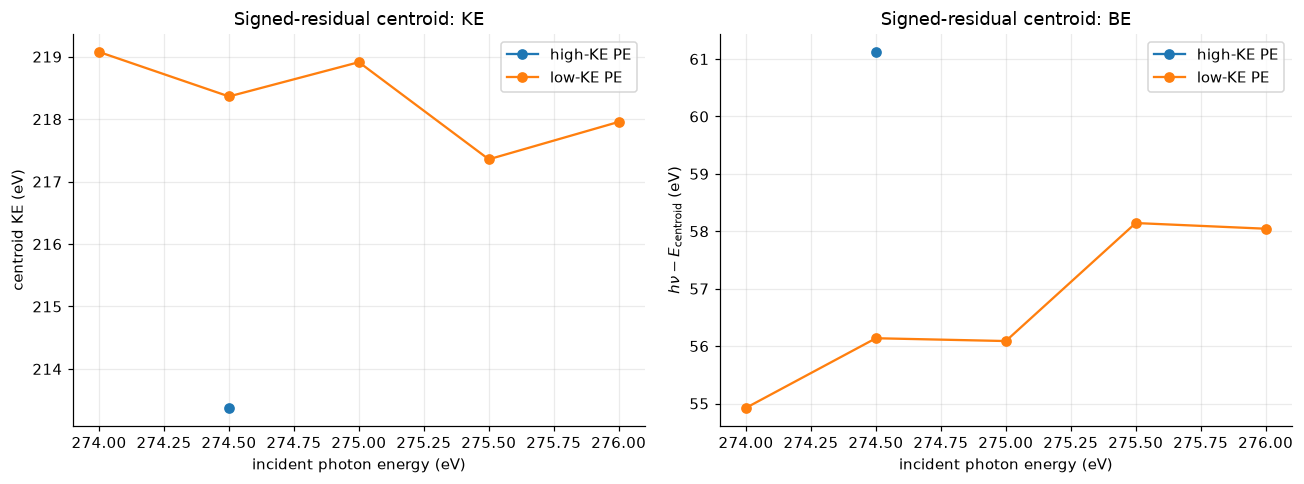

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharex=True)

for label in PE_BE_WINDOWS:
    a = np.array(signed_centroids[label], dtype=float)
    axes[0].plot(a[:, 0], a[:, 2], "o-", label=label)
    axes[1].plot(a[:, 0], a[:, 3], "o-", label=label)

axes[0].set_title("Signed-residual centroid: KE")
axes[0].set_ylabel("centroid KE (eV)")
axes[1].set_title("Signed-residual centroid: BE")
axes[1].set_ylabel(r"$h\nu-E_{\rm centroid}$ (eV)")

for ax in axes:
    ax.set_xlabel("incident photon energy (eV)")
    ax.grid(alpha=0.25)
    ax.legend()

fig.tight_layout()
plt.show()

## 4. Existing electron–electron covariance and GMD partial covariance
The aggregate writer bins the **per-shot TOF count vector** `D`, retaining `D`, `DtD`, `G`, `DtG`, `GtG` as **means**, with `n_per_bin` as exposure. After pooling moments with shot-count weights:

`Cov(Di,Dj) = <Di Dj> − <Di><Dj>`

`pcov(Di,Dj;G) = Cov(Di,Dj) − Cov(Di,G) Cov(Dj,G) / Var(G)`.

These are population covariances (`1/N`), without smoothing or interpolation. Zero/near-zero GMD variance yields unavailable partial covariance. Pooling moments first retains between-bin variation; averaging per-bin covariances would answer a different question. The diagonal includes self-count variance, unlike the unique-pair map.

The full aggregate matrices are large. The helper reuses `AggregatesData` but reads selected `DtD` row blocks only. **Whole native TOF bins** are grouped at native calibrated edges nearest the requested KE grid; both matrix axes use that exact unequal grid. No fractional-bin split is invented. Raw pair maps retain their uniform KE grid. Both use the same calibration and physical KE limits; bin widths and aggregate support are reported.

**Population limits:** existing aggregates include every bunch, GMD bin `[0,12)` here and finite z within their saved edges. Raw diagnostics use `[1,12)` by default and any z when delay is unset. An exact `[1,12)` or arbitrary bunch/sub-z selection cannot be recovered from aggregates. The default aggregate preview uses the first occupied selected cell. Compare shapes/features cautiously; use identical populations for quantitative comparison, with a dedicated aggregate job if necessary.

274.0 eV shapes={'D': (4, 53, 5000), 'DtD': (4, 53, 5000, 5000), 'G': (4, 53), 'DtG': (4, 53, 5000), 'GtG': (4, 53)}; selected 20/53 occupied cells; N=281,159; Var(G)=0.693448
 GMD intervals: [(np.float64(0.0), np.float64(3.0))] stage intervals: [(np.float64(-15000.0), np.float64(-13000.0)), (np.float64(-13000.0), np.float64(-11000.0)), (np.float64(-11000.0), np.float64(-9000.0)), (np.float64(-9000.0), np.float64(-7000.0)), (np.float64(-7000.0), np.float64(-5000.0)), (np.float64(-5000.0), np.float64(-3000.0)), (np.float64(-3000.0), np.float64(-1000.0)), (np.float64(-1000.0), np.float64(1000.0)), (np.float64(1000.0), np.float64(3000.0)), (np.float64(3000.0), np.float64(5000.0)), (np.float64(5000.0), np.float64(7000.0)), (np.float64(7000.0), np.float64(9000.0)), (np.float64(9000.0), np.float64(11000.0)), (np.float64(11000.0), np.float64(13000.0)), (np.float64(13000.0), np.float64(15000.0)), (np.float64(15000.0), np.float64(17000.0)), (np.float64(17000.0), np.float64(19000.0)), (np.float6

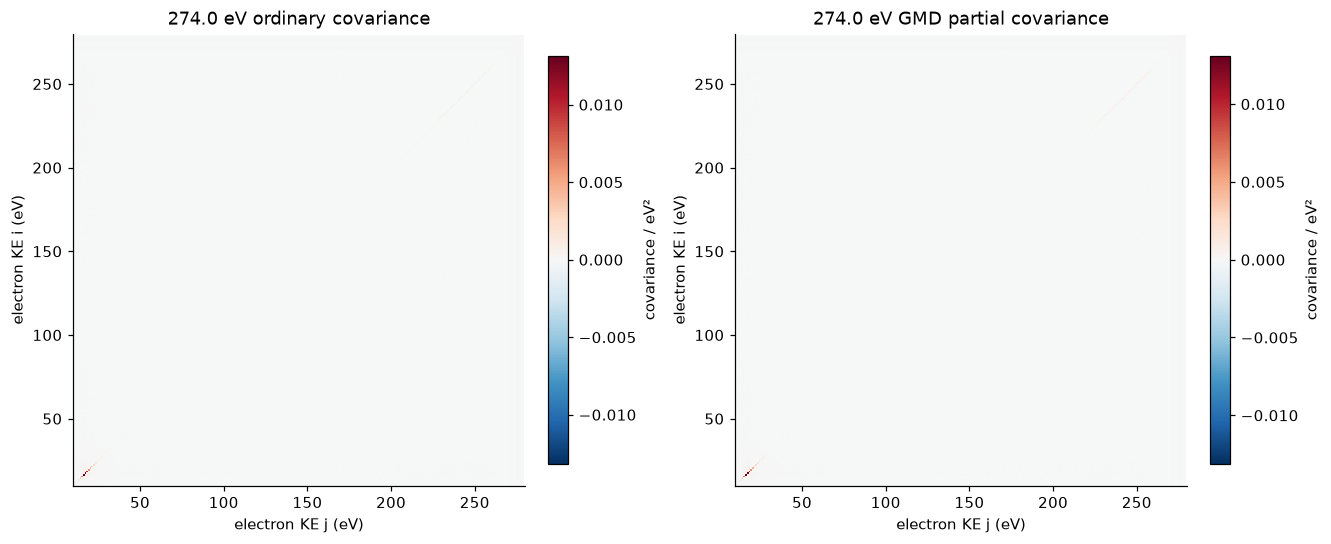

274.5 eV shapes={'D': (4, 53, 5000), 'DtD': (4, 53, 5000, 5000), 'G': (4, 53), 'DtG': (4, 53, 5000), 'GtG': (4, 53)}; selected 20/53 occupied cells; N=370,324; Var(G)=0.665424
 GMD intervals: [(np.float64(0.0), np.float64(3.0))] stage intervals: [(np.float64(-15000.0), np.float64(-13000.0)), (np.float64(-13000.0), np.float64(-11000.0)), (np.float64(-11000.0), np.float64(-9000.0)), (np.float64(-9000.0), np.float64(-7000.0)), (np.float64(-7000.0), np.float64(-5000.0)), (np.float64(-5000.0), np.float64(-3000.0)), (np.float64(-3000.0), np.float64(-1000.0)), (np.float64(-1000.0), np.float64(1000.0)), (np.float64(1000.0), np.float64(3000.0)), (np.float64(3000.0), np.float64(5000.0)), (np.float64(5000.0), np.float64(7000.0)), (np.float64(7000.0), np.float64(9000.0)), (np.float64(9000.0), np.float64(11000.0)), (np.float64(11000.0), np.float64(13000.0)), (np.float64(13000.0), np.float64(15000.0)), (np.float64(15000.0), np.float64(17000.0)), (np.float64(17000.0), np.float64(19000.0)), (np.float6

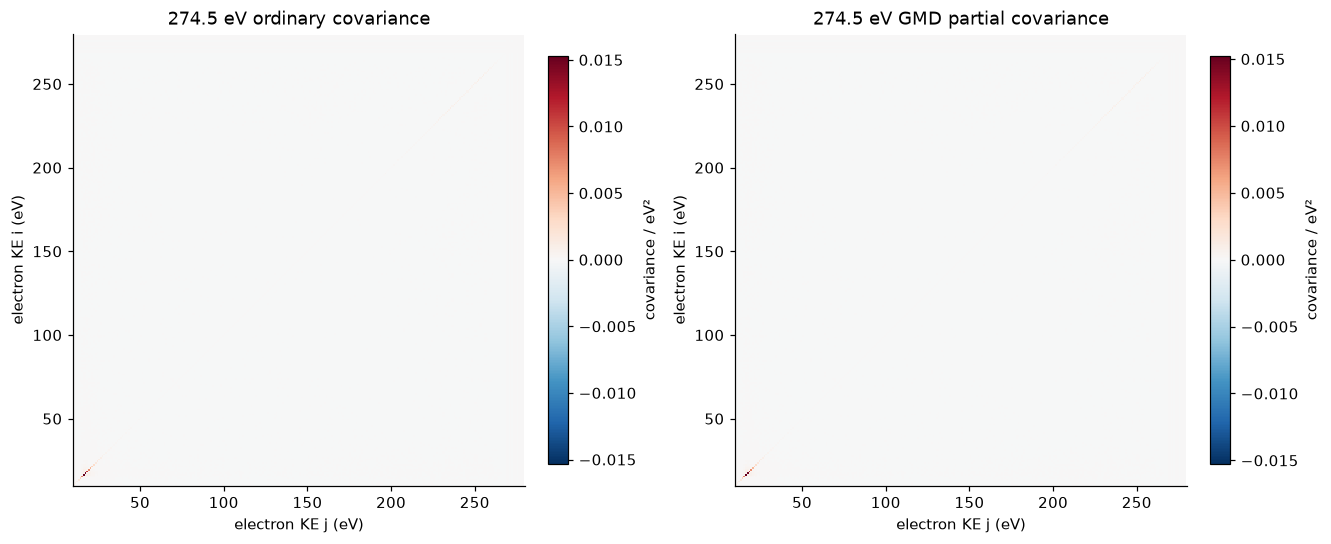

275.0 eV shapes={'D': (4, 53, 5000), 'DtD': (4, 53, 5000, 5000), 'G': (4, 53), 'DtG': (4, 53, 5000), 'GtG': (4, 53)}; selected 20/53 occupied cells; N=388,982; Var(G)=0.599256
 GMD intervals: [(np.float64(0.0), np.float64(3.0))] stage intervals: [(np.float64(-15000.0), np.float64(-13000.0)), (np.float64(-13000.0), np.float64(-11000.0)), (np.float64(-11000.0), np.float64(-9000.0)), (np.float64(-9000.0), np.float64(-7000.0)), (np.float64(-7000.0), np.float64(-5000.0)), (np.float64(-5000.0), np.float64(-3000.0)), (np.float64(-3000.0), np.float64(-1000.0)), (np.float64(-1000.0), np.float64(1000.0)), (np.float64(1000.0), np.float64(3000.0)), (np.float64(3000.0), np.float64(5000.0)), (np.float64(5000.0), np.float64(7000.0)), (np.float64(7000.0), np.float64(9000.0)), (np.float64(9000.0), np.float64(11000.0)), (np.float64(11000.0), np.float64(13000.0)), (np.float64(13000.0), np.float64(15000.0)), (np.float64(15000.0), np.float64(17000.0)), (np.float64(17000.0), np.float64(19000.0)), (np.float6

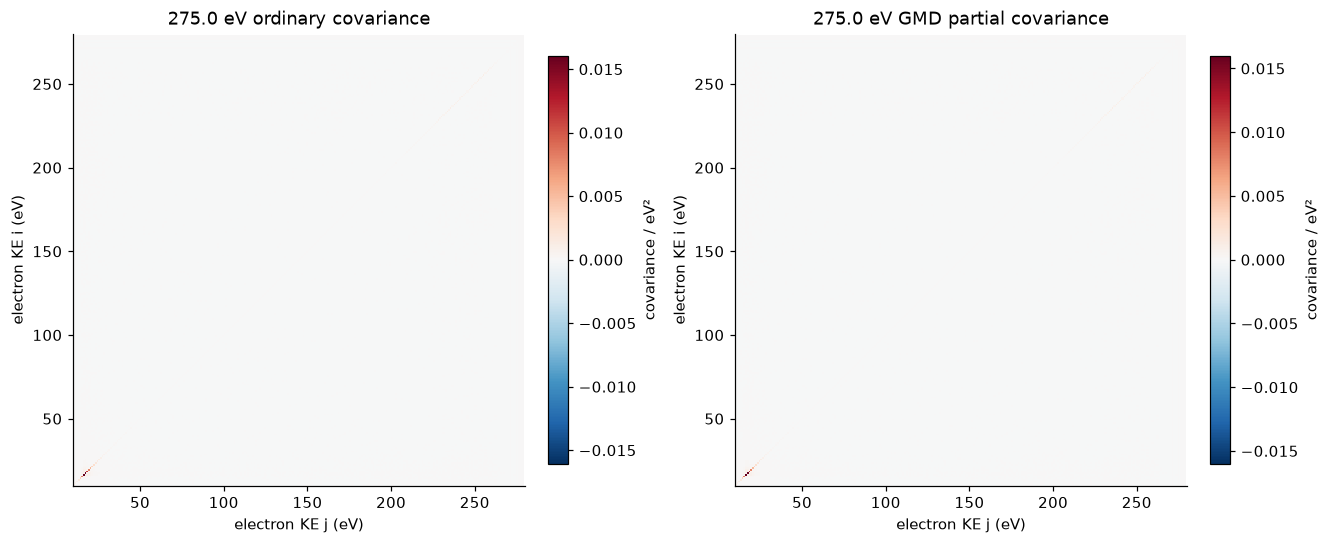

275.5 eV shapes={'D': (4, 53, 5000), 'DtD': (4, 53, 5000, 5000), 'G': (4, 53), 'DtG': (4, 53, 5000), 'GtG': (4, 53)}; selected 20/53 occupied cells; N=446,353; Var(G)=0.698366
 GMD intervals: [(np.float64(0.0), np.float64(3.0))] stage intervals: [(np.float64(-15000.0), np.float64(-13000.0)), (np.float64(-13000.0), np.float64(-11000.0)), (np.float64(-11000.0), np.float64(-9000.0)), (np.float64(-9000.0), np.float64(-7000.0)), (np.float64(-7000.0), np.float64(-5000.0)), (np.float64(-5000.0), np.float64(-3000.0)), (np.float64(-3000.0), np.float64(-1000.0)), (np.float64(-1000.0), np.float64(1000.0)), (np.float64(1000.0), np.float64(3000.0)), (np.float64(3000.0), np.float64(5000.0)), (np.float64(5000.0), np.float64(7000.0)), (np.float64(7000.0), np.float64(9000.0)), (np.float64(9000.0), np.float64(11000.0)), (np.float64(11000.0), np.float64(13000.0)), (np.float64(13000.0), np.float64(15000.0)), (np.float64(15000.0), np.float64(17000.0)), (np.float64(17000.0), np.float64(19000.0)), (np.float6

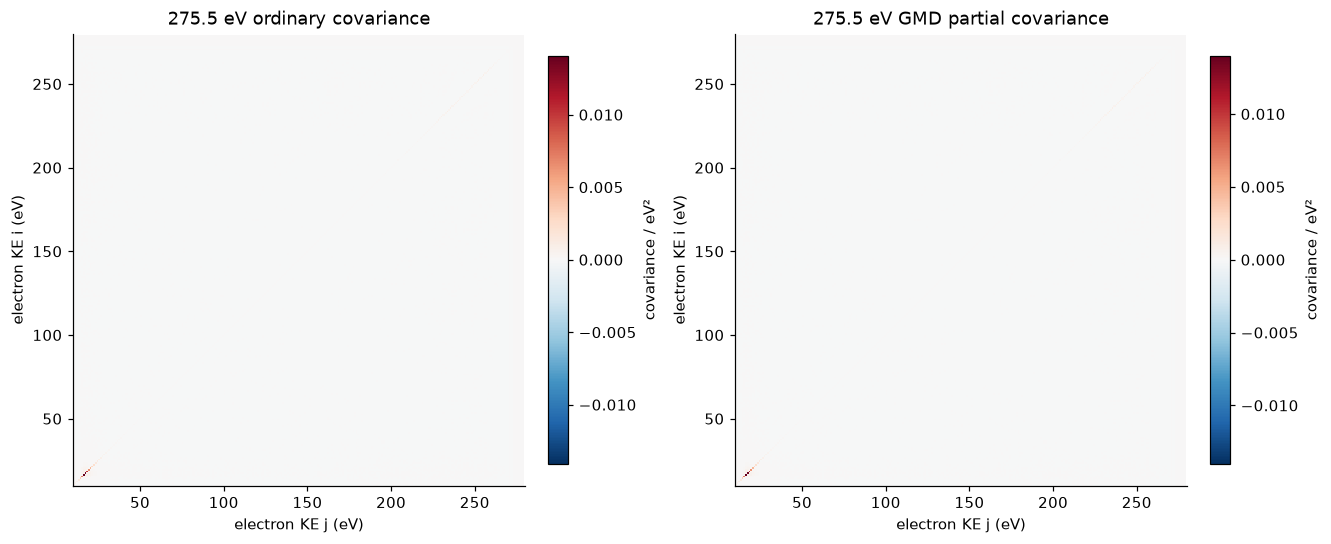

276.0 eV shapes={'D': (4, 53, 5000), 'DtD': (4, 53, 5000, 5000), 'G': (4, 53), 'DtG': (4, 53, 5000), 'GtG': (4, 53)}; selected 20/53 occupied cells; N=595,466; Var(G)=0.75309
 GMD intervals: [(np.float64(0.0), np.float64(3.0))] stage intervals: [(np.float64(-15000.0), np.float64(-13000.0)), (np.float64(-13000.0), np.float64(-11000.0)), (np.float64(-11000.0), np.float64(-9000.0)), (np.float64(-9000.0), np.float64(-7000.0)), (np.float64(-7000.0), np.float64(-5000.0)), (np.float64(-5000.0), np.float64(-3000.0)), (np.float64(-3000.0), np.float64(-1000.0)), (np.float64(-1000.0), np.float64(1000.0)), (np.float64(1000.0), np.float64(3000.0)), (np.float64(3000.0), np.float64(5000.0)), (np.float64(5000.0), np.float64(7000.0)), (np.float64(7000.0), np.float64(9000.0)), (np.float64(9000.0), np.float64(11000.0)), (np.float64(11000.0), np.float64(13000.0)), (np.float64(13000.0), np.float64(15000.0)), (np.float64(15000.0), np.float64(17000.0)), (np.float64(17000.0), np.float64(19000.0)), (np.float64

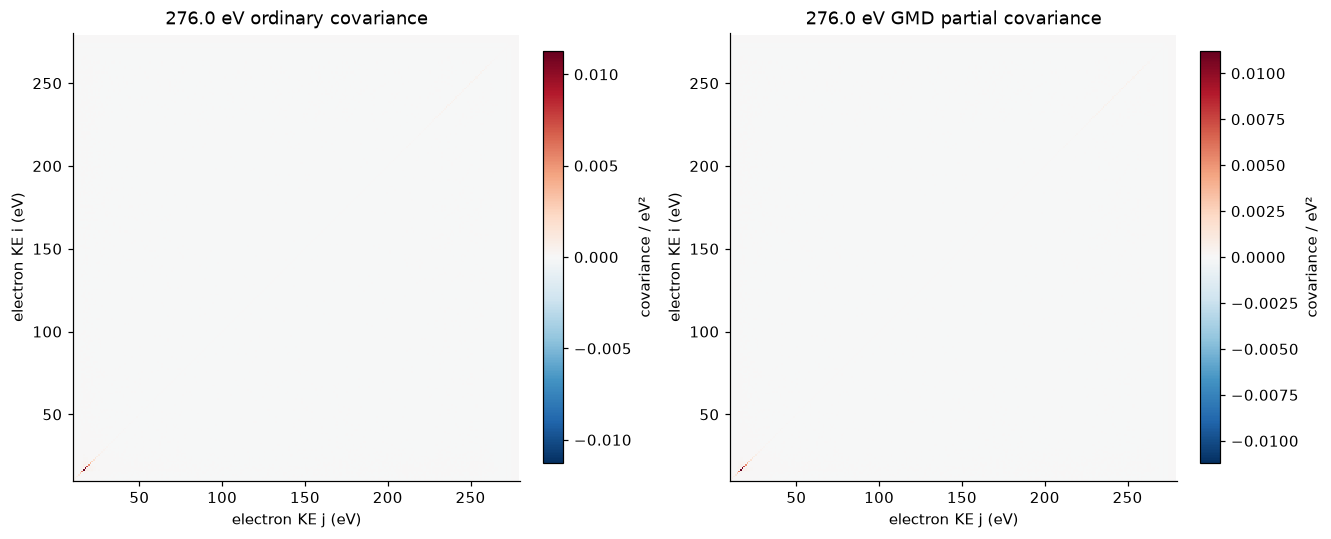

276.5 eV shapes={'D': (4, 53, 5000), 'DtD': (4, 53, 5000, 5000), 'G': (4, 53), 'DtG': (4, 53, 5000), 'GtG': (4, 53)}; selected 1/1 occupied cells; N=5,382,593; Var(G)=0
 GMD intervals: [(np.float64(0.0), np.float64(3.0))] stage intervals: [(np.float64(-1000.0), np.float64(1000.0))]
 KE support=[10.019,279.327] eV; actual widths=[0.5259,1.666] eV


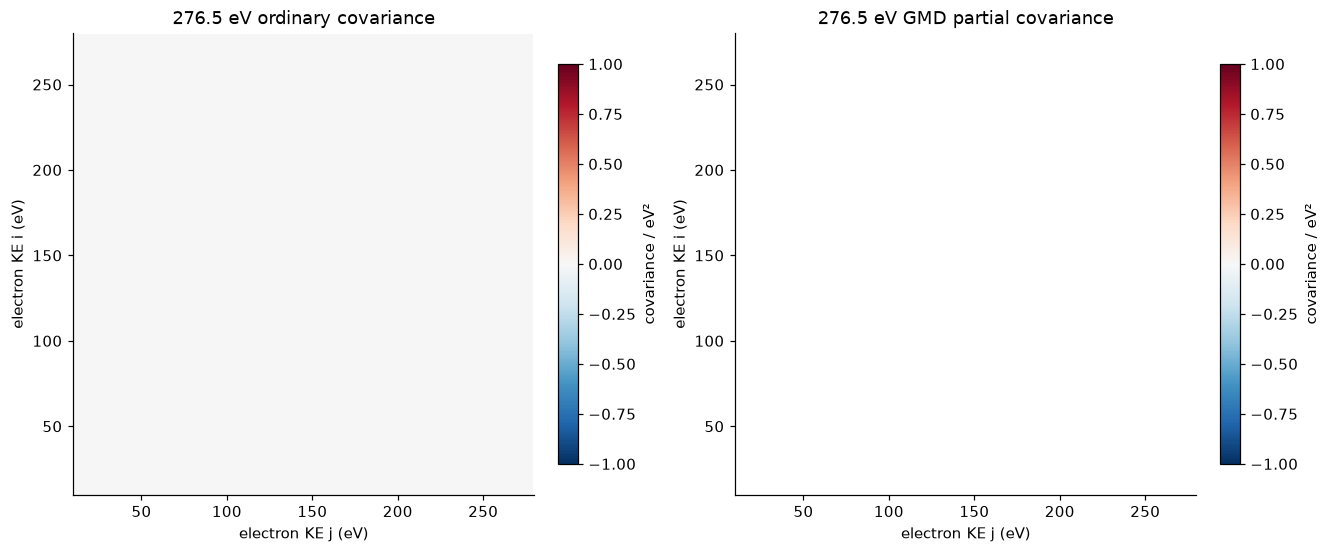

Raw and aggregate populations differ with current defaults; no amplitude-equivalence claim is made.


In [10]:
# Select exact existing bins; pool n-weighted means, then form ordinary and partial covariance.
aggregate_results = {}
for ds in datasets:
    r = read_ee_aggregates(ds, calibration, ke_edges, AGG_GMD_RANGE, AGG_STAGE_RANGE, MAX_AGG_CELLS, AGG_ROW_CHUNK)
    aggregate_results[ds['hv']] = r
    print(f"{ds['hv']:.1f} eV shapes={r['shapes']}; selected {len(r['cells'])}/{r['total_cells']} occupied cells; N={r['shots']:,}; Var(G)={r['var_gmd']:.6g}")
    print(" GMD intervals:", sorted(set(r['gmd_intervals'])), "stage intervals:", r['stage_intervals'])
    print(f" KE support=[{r['edges'][0]:.3f},{r['edges'][-1]:.3f}] eV; actual widths=[{np.diff(r['edges']).min():.4g},{np.diff(r['edges']).max():.4g}] eV")
    fig, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)
    plot_map(axes[0], r['edges'], r['cov'], f"{ds['hv']:.1f} eV ordinary covariance", covariance=True)
    plot_map(axes[1], r['edges'], r['pcov'], f"{ds['hv']:.1f} eV GMD partial covariance", covariance=True)
    plt.show()
print("Raw and aggregate populations differ with current defaults; no amplitude-equivalence claim is made.")

## 5. Moving 10a′ photoelectron gate, free partner axis
Set a justified binding-energy interval `[BE_low, BE_high)`. At each incident energy the PE gate moves to **`[hv−BE_high, hv−BE_low)`**; the partner axis remains at fixed KE. No Auger KE window is selected. Print the bins actually used, because finite binning limits the gate precision.

The triangular coincidence projection includes either electron as the PE: a pair with **both** electrons inside the PE window contributes two electron-tagged partners. Partial covariance projects one selected electron axis of the symmetric map; the diagonal is excluded by default in this projection to avoid self-count variance. Its units and population differ from coincidence. Follow any candidate fixed-KE structure across incident energies and controls before assigning it.

In [7]:
# Whole-bin PE projections; never smooth or interpolate between native grids.
pe_raw, pe_partial = {}, {}
def partial_projection(r, hv):
    edges = r['edges']; centres = (edges[:-1] + edges[1:]) / 2
    lo, hi = hv - PE_BE_WINDOW_EV[1], hv - PE_BE_WINDOW_EV[0]
    chosen = (centres >= lo) & (centres < hi)
    if not chosen.any(): raise ValueError("PE window outside aggregate coverage")
    matrix = r['pcov'].copy()
    if EXCLUDE_COV_DIAGONAL_IN_PROJECTION: np.fill_diagonal(matrix, 0.)
    return matrix @ chosen.astype(float), np.flatnonzero(chosen)

if PE_BE_WINDOW_EV is None:
    print("PE projections unset: configure a justified 10a′ PE_BE_WINDOW_EV in the setup cell.")
else:
    fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True, constrained_layout=True)
    for hv, r in raw.items():
        partner, window, used = coincidence_projection(r['pairs'], ke_edges, hv, PE_BE_WINDOW_EV)
        pe_raw[hv] = partner
        a = aggregate_results[hv]; partial, used_a = partial_projection(a, hv); pe_partial[hv] = partial
        print(f"{hv:.1f} eV: PE KE={window}; raw actual bin support=[{ke_edges[used[0]]:.3f},{ke_edges[used[-1]+1]:.3f}]; aggregate support=[{a['edges'][used_a[0]]:.3f},{a['edges'][used_a[-1]+1]:.3f}]")
        axes[0].stairs(partner / (r['shots'] or np.nan) / ke_widths, ke_edges, label=f"{hv:.1f} eV")
        axes[1].stairs(partial / np.diff(a['edges']), a['edges'], label=f"{hv:.1f} eV")
    axes[0].set(ylabel="PE-tagged partners / selected shot / eV", title="Coincidence PE projection; no partner ROI")
    axes[1].set(xlabel="partner electron KE (eV)", ylabel="partial covariance / eV", title="GMD partial-covariance PE projection")
    axes[1].axhline(0, color='0.5', lw=.8)
    if KE_PLOT_RANGE is not None: axes[1].set_xlim(KE_PLOT_RANGE)
    for ax in axes: ax.legend(ncol=3, fontsize=9)
    plt.show()

PE projections unset: configure a justified 10a′ PE_BE_WINDOW_EV in the setup cell.


## 6. Streamed generic ion gates after ungated diagnostics
Select `Q = any ion hit in [TOF_low, TOF_high)` on the same valid train/bunch shots. Rerun only this section after setting signal/control ROIs in the setup cell and rebuilding `settings`. Gates are Boolean: multiple ions in one ROI do not multiply the shot weight. The control may overlap the signal; the selected-shot overlap is reported. Compare spectra per selected shot and exposure, rather than equal-height curves.

Outputs are the Q electron spectrum, Q unique-pair map, and Q PE-partner spectrum when the PE gate is configured. They are **conditional coincidences**, not third-order or GMD partial covariance. No electron × electron × ion tensor is allocated. Later third-order work needs dedicated streamed moments.

In [8]:
# This pass runs only when at least one explicitly chosen ion ROI exists.
ion_gates = {name: roi for name, roi in [('signal', ION_SIGNAL_ROI), ('control', ION_CONTROL_ROI)] if roi is not None}
gated, pe_ion = {}, {}
if not ion_gates:
    print("Ion-gated analysis unset: choose generic ion TOF ROIs after inspecting the full spectrum.")
else:
    from ee_ion_covariance import iter_shots
    for ds in datasets:
        hv = ds['hv']
        results = accumulate_pairs(ds, settings, calibration, ke_edges, gates=ion_gates, cb=cb_by_energy.get(hv))
        # Ungated recomputation must agree exactly, guarding stale setup/calibration.
        for key in ['single', 'pairs']:
            if not np.array_equal(results['ungated'][key], raw[hv][key]): raise ValueError("Ungated result changed: rerun the notebook from setup")
        gated[hv] = {name: results[name] for name in ion_gates}
        if len(ion_gates) == 2:
            overlap = 0
            for block in iter_shots(ds, settings, load_ions=True):
                masks = [np.any(np.isfinite(block['ions']) & (block['ions'] > 0) & (block['ions'] >= lo) & (block['ions'] < hi), axis=-1) for lo, hi in ion_gates.values()]
                overlap += int(np.sum(block['valid'] & masks[0] & masks[1]))
            print(f"{hv:.1f} eV signal/control shot overlap={overlap:,}")
        fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
        for name, r in gated[hv].items():
            print_stats(f"{hv:.1f} eV / {name} Q", r)
            if r['shots'] == 0: print(" No selected events; spectrum is unavailable.")
            denom = r['sum_norm'] if r['sum_norm'] > 0 else np.nan
            axes[0].stairs(r['single'] / denom / ke_widths, ke_edges, label=name)
            if PE_BE_WINDOW_EV is not None:
                partner, _, _ = coincidence_projection(r['pairs'], ke_edges, hv, PE_BE_WINDOW_EV)
                pe_ion[(hv, name)] = partner
                axes[1].stairs(partner / (r['shots'] or np.nan) / ke_widths, ke_edges, label=name)
        axes[0].set(xlabel="electron KE (eV)", ylabel="electrons / summed exposure / eV", title=f"{hv:.1f} eV Q electron spectrum")
        axes[1].set(xlabel="partner KE (eV)", ylabel="PE-tagged partners / Q shot / eV", title="Q partner spectra" if PE_BE_WINDOW_EV is not None else "PE window unset")
        if KE_PLOT_RANGE is not None:
            for ax in axes: ax.set_xlim(KE_PLOT_RANGE)
        axes[0].legend()
        if PE_BE_WINDOW_EV is not None: axes[1].legend()
        plt.show()
        for name, r in gated[hv].items():
            fig_map, ax_map = plt.subplots(figsize=(6, 5), constrained_layout=True)
            plot_map(ax_map, ke_edges, r['pairs'], f"{hv:.1f} eV / {name} Q coincidence")
            plt.show()


Ion-gated analysis unset: choose generic ion TOF ROIs after inspecting the full spectrum.


## 7. Final diagnostics on the same calibration
Compare single-electron yield, the partner marginal of raw unique pairs, GMD partial covariance, moving-PE partner counts and ion-gated PE partners. Keep their distinct units: coincidence counts and covariance are different observables, and preview populations differ. No curves are rescaled to equal height.

The raw pair marginal counts each member of a real pair once (`row sum + column sum`); same-bin pairs therefore contribute two partners. The partial-covariance marginal excludes the diagonal when requested. Gates may improve contrast by changing the selected population; this alone is neither physical significance nor evidence for Gly²⁺. Assess accidental backgrounds, sideband controls, detector dead time, train variability and calibration validity before making an assignment. A candidate Auger feature should stay at fixed partner KE as the PE gate follows photon energy.

In [ ]:
# Distinct observables, shared KE calibration and plot limits; unavailable gates are labelled.
fig, axes = plt.subplots(5, 1, figsize=(11, 14), sharex=True, constrained_layout=True)
for hv, r in raw.items():
    label = f"{hv:.1f} eV"
    axes[0].stairs(r['single'] / (r['sum_norm'] or np.nan) / ke_widths, ke_edges, label=label)
    marginal = r['pairs'].sum(axis=0) + r['pairs'].sum(axis=1)
    axes[1].stairs(marginal / (r['shots'] or np.nan) / ke_widths, ke_edges, label=label)
    a = aggregate_results[hv]; matrix = a['pcov'].copy()
    if EXCLUDE_COV_DIAGONAL_IN_PROJECTION: np.fill_diagonal(matrix, 0.)
    axes[2].stairs(matrix.sum(axis=1) / np.diff(a['edges']), a['edges'], label=label)
    if hv in pe_raw: axes[3].stairs(pe_raw[hv] / (r['shots'] or np.nan) / ke_widths, ke_edges, label=label)
    for name, q in gated.get(hv, {}).items():
        if (hv, name) in pe_ion:
            axes[4].stairs(pe_ion[(hv, name)] / (q['shots'] or np.nan) / ke_widths, ke_edges, label=f"{label} {name}")
for ax, ylabel, title in zip(axes, ['electrons / exposure / eV', 'pair members / shot / eV', 'partial covariance / eV', 'PE partners / shot / eV', 'PE partners / Q shot / eV'],
    ['Ordinary single-electron spectrum', 'Raw two-electron coincidence marginal', 'GMD partial-covariance marginal (aggregate population)', 'Moving-PE coincidence projection', 'Ion-gated moving-PE projection']):
    ax.set(ylabel=ylabel, title=title)
    handles, labels = ax.get_legend_handles_labels()
    if handles: ax.legend(ncol=3, fontsize=8)
    else: ax.text(.5, .5, "Required PE window / ion ROI unset", transform=ax.transAxes, ha='center')
axes[2].axhline(0, color='0.5', lw=.8)
axes[-1].set_xlabel("electron / partner KE (eV), shared saved eTOF calibration")
if KE_PLOT_RANGE is not None: axes[-1].set_xlim(KE_PLOT_RANGE)
plt.show()
print("No Auger or Gly²⁺ assignment follows from these diagnostic plots alone.")